# Etapa 7 · Poda e fine-tuning de recuperação: quanto dá para tirar da rede

| | |
|---|---|
| **Pergunta** | Quanto dá para remover da rede, e quanto o reajuste recupera? |
| **Entrada** | `entregas/01_dados/` (os pedidos), `entregas/04b_intencao/` (o teto), `entregas/06_destilacao/` (os alunos que seguem, a decisão e o sinal de treino de cada um, que vem das entregas dos professores) e as execuções gravadas pelos comandos de `especialista/experimentos/etapa7.py`. |
| **Entrega** | `entregas/07_poda/`: a curva de qualidade por esparsidade, antes e depois do reajuste; a contraparte estruturada; o que cada poda muda de verdade em parâmetros, bytes e milissegundos; os modelos que seguem para a quantização e o `decisao.json` que diz onde estão. |
| **Pronto quando** | (1) cada variante tem 3 sementes para cada modelo de partida, com o mesmo orçamento de reajuste; (2) a esparsidade pedida é a obtida; (3) nenhum rótulo humano entrou no reajuste dos alunos; (4) cada nível tem a medida antes e depois do reajuste, com comparação pareada contra o mesmo modelo sem poda e intervalo de 95%, no teste; (5) tamanho e latência foram medidos em arquivos gravados e modelos carregados, não estimados; (6) o que segue para a quantização saiu de `dev`, pela regra escrita antes; (7) os modelos entregues reproduzem as respostas do teste. |

**O que é podar.** Uma rede treinada tem mais pesos do que usa. Podar é tirar os que menos fazem falta e depois treinar mais um pouco, para que os que ficaram compensem. Esse treino a mais é o fine-tuning de recuperação; aqui ele é chamado de **reajuste**. Há dois jeitos de tirar: **pesos soltos**, espalhados pelas matrizes, ou **peças inteiras** da rede.

**Artigos de apoio**

- Treinar, podar pelos pesos de menor valor absoluto e treinar de novo: Han et al., *Learning both Weights and Connections for Efficient Neural Networks* ([arXiv 1506.02626](https://arxiv.org/abs/1506.02626)).
- Poda gradual, com a esparsidade subindo durante o treino: Zhu & Gupta, *To prune, or not to prune* ([arXiv 1710.01878](https://arxiv.org/abs/1710.01878)).
- Poda por magnitude em um modelo de tradução, com corte global ou por classe de pesos, com e sem reajuste: See et al., *Compression of Neural Machine Translation Models via Pruning* ([arXiv 1606.09274](https://arxiv.org/abs/1606.09274)).
- A poda por magnitude, simples, compete com métodos mais elaborados: Gale et al., *The State of Sparsity in Deep Neural Networks* ([arXiv 1902.09574](https://arxiv.org/abs/1902.09574)).
- Magnitude contra outros critérios, com a mesma curva cúbica e com destilação durante a poda: Sanh et al., *Movement Pruning* ([arXiv 2005.07683](https://arxiv.org/abs/2005.07683)).
- Máscara travada no reajuste, só com o sinal do professor, e quantização depois da poda: Zafrir et al., *Prune Once for All* ([arXiv 2111.05754](https://arxiv.org/abs/2111.05754)).
- Com que taxa de aprendizado e por quanto tempo reajustar: Renda et al., *Comparing Rewinding and Fine-tuning in Neural Network Pruning* ([arXiv 2003.02389](https://arxiv.org/abs/2003.02389)).
- Poda estruturada, de camadas inteiras a dimensões: Xia et al., *Structured Pruning Learns Compact and Accurate Models* (CoFi, [arXiv 2204.00408](https://arxiv.org/abs/2204.00408)).
- Descartar camadas de um Transformer já treinado: Sajjad et al., *On the Effect of Dropping Layers of Pre-trained Transformer Models* ([arXiv 2004.03844](https://arxiv.org/abs/2004.03844)).
- Importância de uma peça pelo gradiente: Michel et al., *Are Sixteen Heads Really Better than One?* ([arXiv 1905.10650](https://arxiv.org/abs/1905.10650)); Molchanov et al., *Pruning Convolutional Neural Networks for Resource Efficient Inference* ([arXiv 1611.06440](https://arxiv.org/abs/1611.06440)).
- Tirar features de uma tabela de palavras e n-gramas: Joulin et al., *FastText.zip* ([arXiv 1612.03651](https://arxiv.org/abs/1612.03651)).
- Guardar só os pesos que ficaram, e a ordem podar e depois quantizar: Han et al., *Deep Compression* ([arXiv 1510.00149](https://arxiv.org/abs/1510.00149)).
- Como reportar poda (tamanho e velocidade, controle, sementes): Blalock et al., *What is the State of Neural Network Pruning?* ([arXiv 2003.03033](https://arxiv.org/abs/2003.03033)). Parâmetros, bytes e tempo não são a mesma medida: Dehghani et al., *The Efficiency Misnomer* ([arXiv 2110.12894](https://arxiv.org/abs/2110.12894)).
- Treinar do zero a rede menor pode dar o mesmo que podar e reajustar: Liu et al., *Rethinking the Value of Network Pruning* ([arXiv 1810.05270](https://arxiv.org/abs/1810.05270)).
- Protocolo de latência: Reddi et al., *MLPerf Inference Benchmark* ([arXiv 1911.02549](https://arxiv.org/abs/1911.02549)). Variação entre sementes: Reimers & Gurevych ([arXiv 1707.09861](https://arxiv.org/abs/1707.09861)).

**Roteiro**

1. Onde estão os pesos
2. O que ficou decidido antes de medir
3. Como a poda funciona
4. As execuções
5. Pesos soltos: antes e depois do reajuste
6. De uma vez ou gradual?
7. Peças inteiras
8. O que muda de verdade: parâmetros, bytes e milissegundos
9. O que segue para a quantização
10. Entrega
11. Resposta

In [1]:
import json
import shutil
import tempfile
from collections import Counter
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

from especialista import visual
from especialista.avaliacao import eficiencia, qualidade, resultados
from especialista.avaliacao.previsao import carregar_previsoes, ouro, salvar_previsoes
from especialista.caminhos import RAIZ, entrega
from especialista.compressao import poda
from especialista.dados import massive
from especialista.experimentos import etapa6, etapa7
from especialista.modelos.diet import SistemaDiet
from especialista.modelos.diet.features import features_do_texto

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 200)
torch.set_num_threads(1)

PASTA = entrega("07_poda")
SEMENTES, NIVEIS, VARIANTES = etapa7.SEMENTES, etapa7.ESPARSIDADES, etapa7.VARIANTES
EPOCAS, RAMPA, CORTES = etapa7.EPOCAS, etapa7.EPOCAS_DE_RAMPA, etapa7.PASSOS_ENTRE_CORTES
assert (EPOCAS, RAMPA, CORTES) == (30, 15, 100), "O texto deste notebook foi gerado com outro orçamento de reajuste: gere o notebook de novo."

MODELOS = etapa7.modelos_a_podar()     # o aluno principal vem primeiro; sem alunos, é o teto
PRINCIPAL = next(iter(MODELOS))
ALUNOS = [m for m in MODELOS if MODELOS[m]["variante_da_etapa_6"]]
CURTO = {m: MODELOS[m]["curto"] for m in MODELOS}

DE_UMA_VEZ = {s: f"magnitude_{s}" for s in (*NIVEIS, *etapa7.EXTRAS)}   # os níveis do plano e os dois extras
TOPO = max(DE_UMA_VEZ)                                                    # a maior esparsidade testada
GRADUAL = {s: f"gradual_{s}" for s in NIVEIS}
LINHAS = {s: f"linhas_{s}" for s in NIVEIS}
PECAS = [*LINHAS.values(), "sem_camada"]
PODADAS = [v for v in VARIANTES if v != "sem_poda"]
COM_ANTES = [v for v in PODADAS if VARIANTES[v]["familia"] not in etapa7.SEM_ANTES]
SOLTAS = [v for v in PODADAS if VARIANTES[v]["familia"] in etapa7.PESOS_SOLTOS]

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
gabarito = {"dev": ouro(dev), "test": ouro(teste)}
TRES = ("intent_acc", "slot_f1", "exact_match")   # as três métricas das leituras


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x):
    return f"{100 * x:+.1f}".replace(".", ",").replace("-", "−")


def mb(x):
    return num(x / 1e6, 1)


def com_intervalo(linha):
    return f"{dif(linha['diferenca'])} ({dif(linha['ic_min'])} a {dif(linha['ic_max'])})"


def valor_com_intervalo(linha):
    return f"{pts(linha['valor'])} ({pts(linha['ic_min'])} a {pts(linha['ic_max'])})"


def posicao(linha):
    """Onde B fica em relação a A numa comparação pareada B − A."""
    return "acima" if linha["ic_min"] > 0 else "abaixo" if linha["ic_max"] < 0 else "sem diferença distinguível"


def trio(linha, coluna_do_valor="valor"):
    """Valor e intervalo de uma linha de tabela, em pontos percentuais, para os gráficos."""
    return tuple(100 * linha[c] for c in (coluna_do_valor, "ic_min", "ic_max"))


def lista(itens, vazio="nenhum"):
    """"a", "a e b", "a, b e c"."""
    itens = [str(i) for i in itens]
    return vazio if not itens else itens[0] if len(itens) == 1 else ", ".join(itens[:-1]) + " e " + itens[-1]


def minusculo(texto):
    return texto[0].lower() + texto[1:]


def maiusculo(texto):
    return texto[0].upper() + texto[1:]


curva = visual.curva_com_intervalo   # a curva de qualidade por esparsidade

## 1. Onde estão os pesos

Antes de decidir o que tirar, é preciso saber onde a rede guarda os seus parâmetros. A rede é a mesma para o teto e para os alunos (a da Etapa 3, com a configuração da Etapa 4b). Os pesos mostrados nesta seção são os do modelo principal da etapa, semente 0, como ele chegou: sem poda.

In [2]:
de_partida = {m: SistemaDiet.carregar(MODELOS[m]["pasta"] / "semente_0", "cpu") for m in MODELOS}
rede = de_partida[PRINCIPAL].modelo
tensores = poda.por_tensor(rede)
total = int(tensores["pesos"].sum())


def parte_de(tensor):
    if tensor.startswith("tabela"):
        return "B. Tabela de features"
    if tensor.startswith(("projecao", "marca_cls")):
        return "C. Projeção e CLS"
    if tensor.startswith(("blocos", "norma_final")):
        return "D. Encoder"
    if tensor.startswith(("cls_para_rotulo", "vetor_da_intencao", "atalho")):
        return "E. Cabeça de intenção"
    if tensor.startswith(("emissao", "crf")):
        return "F. Cabeça de entidades (CRF)"
    return "G. Cabeça de máscara (só no treino)"


tensores["parte"] = [parte_de(t) for t in tensores.index]
por_parte = pd.DataFrame({
    "pesos": tensores.groupby("parte")["pesos"].sum(),
    "podaveis": tensores[tensores["podavel"]].groupby("parte")["pesos"].sum(),
}).fillna(0).astype(int)
assert por_parte["pesos"].to_dict() == rede.parametros_por_parte()   # a mesma conta da Etapa 3

n_features, d_features = rede.tabela.weight.shape
pesos_de_um_bloco = sum(p.numel() for p in rede.blocos[-1].parameters())
peca = {
    "B. Tabela de features": f"linhas: {n(n_features)} features, {d_features} pesos em cada um",
    "D. Encoder": f"a camada de cima: {n(pesos_de_um_bloco)} pesos",
}
print(f"Modelo: {MODELOS[PRINCIPAL]['nome']}, semente 0. Parâmetros: {n(total)}.")
pd.DataFrame({
    "parâmetros": por_parte["pesos"].map(n),
    "parte da rede": (por_parte["pesos"] / total).map(lambda v: pts(v) + "%"),
    "entram na poda por magnitude": por_parte["podaveis"].map(n),
    "peça inteira que a poda estruturada tira": [peca.get(parte, "—") for parte in por_parte.index],
})

Modelo: Aluno A (rótulos do Claude Haiku 5.5), semente 0. Parâmetros: 4.895.834.


,parâmetros,parte da rede,entram na poda por magnitude,peça inteira que a poda estruturada tira
parte,,,,
B. Tabela de features,3.225.856,"65,9%",3.225.856,"linhas: 25.202 features, 128 pesos em cada um"
C. Projeção e CLS,33.280,"0,7%",32.768,—
D. Encoder,1.581.440,"32,3%",1.572.864,a camada de cima: 790.464 pesos
E. Cabeça de intenção,6.340,"0,1%",0,—
F. Cabeça de entidades (CRF),41.070,"0,8%",0,—
G. Cabeça de máscara (só no treino),7.848,"0,2%",0,—


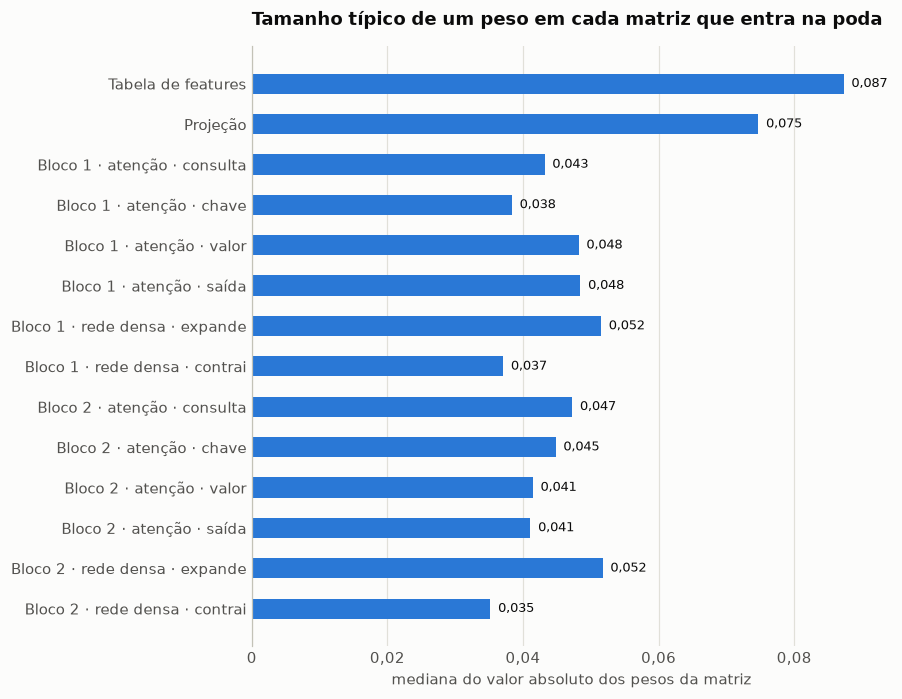


**Leitura.**

- Entram na poda por magnitude 14 matrizes, com 4.831.488 pesos: 98,7% da rede. Só a tabela de features tem 65,9%; o encoder, 32,3%.
- **O tamanho típico de um peso muda de matriz para matriz.** A mediana do valor absoluto vai de 0,035 (Bloco 2 · rede densa · contrai) a 0,087 (Tabela de features), 2,5 vezes mais. Parte disso já vem do sorteio inicial: a tabela nasce com desvio-padrão de 0,1, e as matrizes do encoder, com menos da metade disso. Um mesmo limite de corte para a rede inteira trataria matrizes diferentes de forma diferente só por causa da escala.
- **As linhas da tabela têm todas uma norma parecida.** As 25.202 linhas nascem com norma perto de 1,13 e terminam o treino entre 0,76 e 2,60 (mediana 1,45). A norma quase não acompanha quantas vezes o feature aparece no treino (correlação de postos de −0,25): um feature visto 2 vezes tem norma típica de 1,48. Das 20 linhas de menor norma, 13 são n-gramas de um caractere só, que aparecem em quase toda palavra.


In [3]:
ROTULO_DA_MATRIZ = {"tabela.weight": "Tabela de features", "projecao.weight": "Projeção"}
for i in range(len(rede.blocos)):
    for matriz in ("consulta", "chave", "valor", "saida"):
        ROTULO_DA_MATRIZ[f"blocos.{i}.atencao.{matriz}.weight"] = f"Bloco {i + 1} · atenção · {matriz.replace('saida', 'saída')}"
    ROTULO_DA_MATRIZ[f"blocos.{i}.expande.weight"] = f"Bloco {i + 1} · rede densa · expande"
    ROTULO_DA_MATRIZ[f"blocos.{i}.contrai.weight"] = f"Bloco {i + 1} · rede densa · contrai"

podaveis = tensores[tensores["podavel"]]
mediana = {nome: float(rede.get_parameter(nome).detach().abs().median()) for nome in podaveis.index}
fig, ax = visual.barras_em_ordem(
    {ROTULO_DA_MATRIZ[nome]: valor for nome, valor in mediana.items()},
    "Tamanho típico de um peso em cada matriz que entra na poda", "mediana do valor absoluto dos pesos da matriz",
    formato=lambda v: num(v, 3),
)
visual.salvar(fig, PASTA, "tamanho_dos_pesos")
plt.show()

# As linhas da tabela: a norma de uma linha diz se o feature é útil?
vocabulario = list(de_partida[PRINCIPAL].featurizador.vocabulario)
vezes = Counter(f for tokens in treino["tokens"] for palavra in tokens for f in features_do_texto(palavra))
frequencia = pd.Series([vezes[f] for f in vocabulario], index=vocabulario)
norma = pd.Series(rede.tabela.weight.detach().norm(dim=1).numpy(), index=vocabulario)
correlacao = norma.corr(frequencia, method="spearman")
menores = norma.nsmallest(20).index
de_um_caractere = sum(len(f) == 3 for f in menores)   # "g:" e um caractere

maior, menor = max(mediana, key=mediana.get), min(mediana, key=mediana.get)
display(Markdown(f"""
**Leitura.**

- Entram na poda por magnitude {len(podaveis)} matrizes, com {n(podaveis['pesos'].sum())} pesos: {pts(podaveis['pesos'].sum() / total)}% da rede. Só a tabela de features tem {pts(por_parte.loc['B. Tabela de features', 'pesos'] / total)}%; o encoder, {pts(por_parte.loc['D. Encoder', 'pesos'] / total)}%.
- **O tamanho típico de um peso muda de matriz para matriz.** A mediana do valor absoluto vai de {num(mediana[menor], 3)} ({ROTULO_DA_MATRIZ[menor]}) a {num(mediana[maior], 3)} ({ROTULO_DA_MATRIZ[maior]}), {num(mediana[maior] / mediana[menor], 1)} vezes mais. Parte disso já vem do sorteio inicial: a tabela nasce com desvio-padrão de 0,1, e as matrizes do encoder, com menos da metade disso. Um mesmo limite de corte para a rede inteira trataria matrizes diferentes de forma diferente só por causa da escala.
- **As linhas da tabela têm todas uma norma parecida.** As {n(n_features)} linhas nascem com norma perto de {num(0.1 * d_features ** 0.5, 2)} e terminam o treino entre {num(norma.min(), 2)} e {num(norma.max(), 2)} (mediana {num(norma.median(), 2)}). A norma quase não acompanha quantas vezes o feature aparece no treino (correlação de postos de {num(correlacao, 2).replace('-', '−')}): um feature visto {n(frequencia.min())} vezes tem norma típica de {num(norma[frequencia == frequencia.min()].median(), 2)}. Das 20 linhas de menor norma, {de_um_caractere} são n-gramas de um caractere só, que aparecem em quase toda palavra.
"""))

## 2. O que ficou decidido antes de medir

Cada decisão abaixo foi escrita, e posta no código (`especialista/compressao/poda.py` e `especialista/experimentos/etapa7.py`), antes das execuções desta etapa e antes de existir qualquer medida dos alunos.

**O que já tinha sido visto.** O desenho foi feito com o teto, na CPU. Viram-se: os pesos dos modelos (seção 1); os históricos de treino da Etapa 4b; um ensaio de 2 épocas, para conferir o código, que mostrou que recomeçar o treino atrapalha o modelo nas primeiras épocas (daí a regra do ponto de partida, no item 7) e que a norma é pior que a importância para escolher linhas; e um piloto com o orçamento de verdade, numa semente do teto, em `dev`, em que a rede recuperou quase tudo com 90% dos pesos em zero (daí os dois níveis extras, no item 4). O ensaio também deixou ver, no teste, o teto podado sem reajuste, que não depende de treino. Nenhuma decisão usou o teste.

**1. Quem é podado, e com que sinal é reajustado.** Os alunos que a Etapa 6 marcou para seguir e, como referência, o teto. O reajuste usa **o mesmo sinal com que o modelo aprendeu**: um aluno é reajustado com os rótulos (ou os logits) do seu professor, e a época de parada é escolhida no `dev` rotulado pelo mesmo professor. Nenhum rótulo humano entra no reajuste de um aluno; senão a linha "aluno + poda" mudaria duas coisas de uma vez. O teto é reajustado com os rótulos humanos, que são o sinal dele. Zafrir et al. fazem o mesmo no reajuste de um modelo esparso (só o sinal do professor), e Sanh et al. mostram que podar com o sinal do professor ajuda qualquer critério de poda. Os rótulos humanos de `dev` só aparecem na decisão da seção 9; os do teste, só nos resultados.

**2. Quais pesos entram na poda por magnitude.** As matrizes da entrada e do encoder: a tabela de features, a projeção e as seis matrizes de cada bloco (quatro da atenção, duas da rede densa). Ficam de fora os vieses, as normalizações, a tabela de posição relativa e as cabeças de intenção, de entidades e de máscara: somam pouco mais de 1% dos parâmetros, e cada um pesa muito na saída. É o recorte de Zhu & Gupta e de Zafrir et al.: podar as matrizes das camadas grandes. Sanh et al. congelam a tabela de embeddings e Zafrir et al. podam só as camadas lineares do encoder; aqui a tabela entra, porque guarda dois terços da rede. Zhu & Gupta e See et al. também podam as tabelas de embeddings.

**3. O corte é por matriz, não global.** Cada matriz perde a mesma fração dos seus pesos, os de menor valor absoluto dentro dela (Zhu & Gupta; é o "class-uniform" de See et al.). Um limite único para a rede inteira compararia pesos de escalas diferentes (seção 1) e cortaria mais o encoder do que a tabela só por causa do sorteio inicial. A literatura não fecha a questão: See et al. acham o corte global melhor numa rede em que todas as matrizes nascem na mesma escala, Blalock et al. veem o global na frente para um mesmo tamanho, Sanh et al. não veem diferença relevante, e Zhu & Gupta usam o corte por matriz. O corte global não foi testado aqui.

**4. Os níveis.** 30, 50, 70 e 90% dos pesos podáveis em zero, os do plano, em todas as formas de poda. A poda de uma vez tem dois níveis a mais, 95 e 98% (20 e 50 vezes menos pesos), para achar onde a rede quebra. Eles entraram depois do piloto no teto, que olhou só `dev` e indicou que 90% podem não bastar para ver a queda; Blalock et al. pedem pontos que cheguem a dezenas de vezes de compressão. A **esparsidade** é sempre a fração dos pesos podáveis em zero; a seção 8 mostra quantos parâmetros da rede inteira ficam diferentes de zero em cada nível.

**5. Poda de uma vez, com a medida antes e depois** (Han et al.). Os pesos saem todos de uma vez. Mede-se o modelo assim, sem reajuste (**antes**). Depois ele é reajustado com a **máscara travada**: a cada passo do otimizador, os pesos que saíram voltam a zero. Mede-se de novo (**depois**). A diferença entre as duas medidas é o que o reajuste recupera.

**6. Poda gradual** (Zhu & Gupta). A máscara aperta durante o treino. A esparsidade segue a curva cúbica do artigo, de zero até o nível pedido:

$$s(t) = s_\text{final}\cdot\left(1 - \left(1 - \frac{t}{T}\right)^3\right)$$

- A rampa ocupa as primeiras 15 épocas, e a máscara é refeita a cada 100 passos de treino (o artigo testa de 100 a 1.000 e não vê diferença).
- Nas 15 épocas restantes a máscara fica travada, como o período final de Sanh et al.
- Só as épocas em que a rede já está na esparsidade final concorrem a melhor ponto.
- Na poda gradual não existe "antes do reajuste": o treino corre junto com a poda.

**7. O orçamento do reajuste é o mesmo em todas as execuções: 30 épocas.** O resto da receita é o de quem treinou o modelo (Etapa 4b): Adam com taxa de 0,001, lote crescendo de 64 para 128, lotes balanceados por intenção, média móvel dos pesos, a mesma perda.

- **Por que 30 épocas.** No treino do teto a partir do zero, o exact match em `dev` já estava a menos de meio ponto do seu melhor valor na época 20, nas três sementes, e o melhor ponto ficou nas épocas 25, 40 e 45 (históricos da Etapa 4b). Uma rede podada parte de pesos treinados e recebe mais passos do que a rede precisou para aprender do nada. Renda et al. medem que reajustar com a agenda do treino rende mais que o reajuste comum quando dura de 25% a 90% do treino original, e que o ganho satura perto da metade; 30 épocas são 38% das 80 do treino original.
- **Por que a mesma taxa de aprendizado.** O treino original não diminui a taxa: aumenta o lote. O reajuste refaz esse caminho, do lote de 64 ao de 128. É o que Renda et al. recomendam (repetir a agenda do treino em vez de reajustar só com a taxa final, a menor), e Zhu & Gupta avisam que com taxa pequena demais a rede não se recupera do corte.
- **Desvio declarado.** Han et al. diminuem a taxa e o dropout no reajuste. Aqui a receita não muda de um nível para o outro, para que cada linha da tabela mude uma coisa só.
- **Parada.** A cada 5 épocas o modelo é medido no `dev` de quem o treinou (humano para o teto, rotulado pelo professor para os alunos), e fica o melhor ponto em exact match.
- **O ponto de partida também concorre.** O modelo logo depois do corte, antes de qualquer passo, entra na disputa como "época 0". Se nenhuma época do reajuste for melhor que ele em `dev`, o modelo sai do reajuste como entrou. Um reajuste recomeça o treino (otimizador novo, lote pequeno) e pode atrapalhar um modelo que não precisava de conserto; com esta regra ele só fica quando ajuda. Não vale para a poda gradual, em que o ponto de partida ainda não está na esparsidade final.

**8. Um controle: o mesmo reajuste, sem tirar nada.** Mais 30 épocas de treino podem, sozinhas, mudar o modelo. O controle mede esse efeito, para que ele não seja atribuído à poda. Blalock et al. pedem que todo resultado de poda venha ao lado de um controle; aqui são dois, o modelo sem poda e o modelo sem poda com o mesmo reajuste.

**9. A contraparte estruturada: duas peças inteiras.**

- **Linhas da tabela de features**, em 30, 50, 70 e 90% das linhas. Cada linha é um feature (uma palavra ou um n-grama); sem a linha, o feature sai do vocabulário. É onde estão dois terços dos parâmetros. Saem primeiro as linhas de menor **importância**: quanto a perda de treino mudaria, em primeira ordem, se a linha fosse apagada, |linha · gradiente|, na média dos lotes do treino do próprio modelo. É a medida de Michel et al. para cabeças de atenção, que vem da expansão de Taylor de Molchanov et al. Joulin et al., numa tabela do mesmo tipo, usam a norma da linha. Aqui as linhas têm todas uma norma parecida, e as de menor norma são as dos features mais frequentes (seção 1), então a norma não foi o critério escolhido. Ela fica como comparação, que não custa treino: mede-se em `dev`, sem reajuste, o modelo depois de tirar as mesmas frações de linhas pela norma.
- **A camada de cima do encoder**, que é o que o plano pede. Sajjad et al. comparam várias formas de descartar camadas e ficam com a mais simples, tirar as de cima. Em Xia et al., são as camadas inteiras que mais aceleram a rede.
- As duas peças passam pelo mesmo reajuste, com antes e depois. A rede que sobra é uma rede comum, menor: não precisa de máscara.
- **Desvio declarado.** O CoFi de Xia et al. aprende o que tirar durante o treino, com máscaras e destilação camada a camada. Aqui o critério é fixo e o corte é feito de uma vez. As peças menores do CoFi (cabeças de atenção, unidades da rede densa) não foram testadas.

**10. O que se mede em cada modelo podado.**

- **Qualidade**, na régua do projeto: as 4 métricas com intervalo de 95%, média de 3 sementes, e a comparação pareada com o mesmo modelo sem poda (as mesmas 3 sementes).
- **Eficiência**, medida e não estimada: parâmetros diferentes de zero; tamanho em disco de três jeitos (o arquivo comum do projeto, o arquivo comum com zip, e um arquivo esparso que grava só os pesos que ficaram); latência no protocolo da Etapa 2 (uma consulta por vez, 1 núcleo de CPU), na execução comum e numa execução esparsa, que só faz as contas dos pesos diferentes de zero.
- **O que se espera, antes de medir.** Zerar pesos soltos não muda o arquivo comum (um zero ocupa os mesmos 4 bytes) nem a latência comum (um zero entra nas mesmas contas). Só o armazenamento e a execução que pulam os zeros podem mostrar ganho. Tirar peças inteiras muda os dois sem nada de especial. Dehghani et al. mostram que parâmetros, bytes e tempo não andam juntos; por isso os três são reportados.

**11. A regra do que segue para a quantização** (em `etapa7.quem_segue`), aplicada a cada modelo de partida, em `dev`, com os rótulos humanos:

1. Uma variante **passa** se o exact match dela, depois do reajuste, não for distinguivelmente menor que o do modelo sem poda: o intervalo de 95% da diferença pareada não fica todo abaixo de zero.
2. A **principal** é a variante que passa com o **menor arquivo comum**. É esse arquivo, com todos os pesos gravados, que a quantização e uma execução comum consomem, e só tirar peças inteiras o diminui. Se nenhuma peça inteira passa, a principal é o modelo sem poda.
3. A **secundária** é a dos **pesos soltos** que passa com a maior esparsidade. Se as duas formas (de uma vez e gradual) passam nessa esparsidade, a de maior exact match; se empatam, a de uma vez. O ganho dela depende de um formato que aproveite os zeros; ela segue para a Etapa 8 medir o que a quantização e a compressão fazem com ela.

Seguem até dois modelos por modelo de partida, um de cada tipo. O teste é aberto para todos os níveis, porque a curva inteira é o resultado da etapa; a decisão sai só de `dev`.

**12. Como ler os resultados.** Han et al. veem a rede aguentar perto de metade dos pesos a menos sem reajuste, e muito mais com ele. See et al., num modelo de tradução, veem 40% sem reajuste e 80% com ele. O plano espera que em 30% não haja queda para recuperar e que o reajuste importe de 50% para cima. Liu et al. lembram que, na poda estruturada, treinar do zero a rede menor pode dar o mesmo resultado: essa comparação não é feita aqui.

**13. A grade.** Para cada modelo de partida e cada semente: o controle, 6 níveis de uma vez, 4 níveis graduais, 4 níveis de linhas e a camada. São 16 execuções de 30 épocas por modelo e semente. Ficaram de fora, por orçamento: o corte global, ciclos repetidos de poda e reajuste (Han et al.), a combinação de peças inteiras com pesos soltos e o treino do zero da rede menor.

## 3. Como a poda funciona

### 3.1 O corte por magnitude

Dentro de uma matriz, os pesos são postos em ordem de valor absoluto, e os menores saem. O gráfico mostra os pesos de uma das matrizes do encoder e onde cada nível corta: tudo à esquerda da linha vira zero.

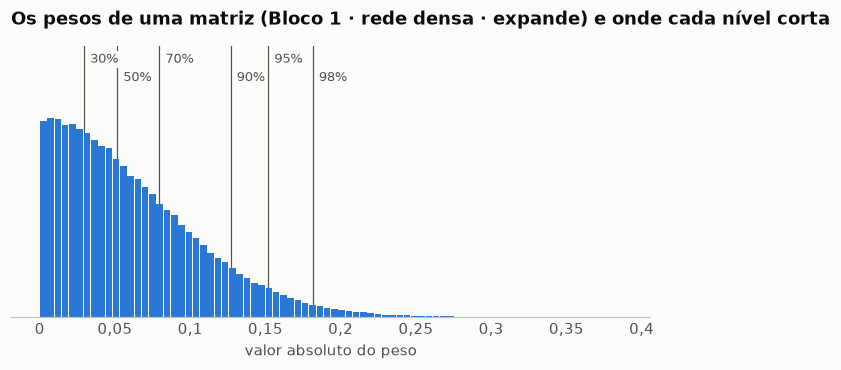


**Leitura.** A matriz tem 262.144 pesos, e a maior parte é pequena: metade tem valor absoluto abaixo de 0,052. Para chegar a 98% é preciso cortar pesos de até 0,181, 6,2 vezes o limite dos 30%. Cada nível a mais tira pesos maiores, que fazem mais falta.


In [4]:
exemplo = "blocos.0.expande.weight"
tamanhos = rede.get_parameter(exemplo).detach().abs().flatten().numpy()
limites = {s: float(np.quantile(tamanhos, s / 100)) for s in DE_UMA_VEZ}
fig, ax = visual.histograma(
    tamanhos, f"Os pesos de uma matriz ({ROTULO_DA_MATRIZ[exemplo]}) e onde cada nível corta", "valor absoluto do peso",
    marcas={f"{s}%": limite for s, limite in limites.items()}, classes=80,
)
visual.salvar(fig, PASTA, "corte_por_magnitude")
plt.show()

display(Markdown(f"""
**Leitura.** A matriz tem {n(len(tamanhos))} pesos, e a maior parte é pequena: metade tem valor absoluto abaixo de {num(limites[50], 3)}. Para chegar a {TOPO}% é preciso cortar pesos de até {num(limites[TOPO], 3)}, {num(limites[TOPO] / limites[NIVEIS[0]], 1)} vezes o limite dos {NIVEIS[0]}%. Cada nível a mais tira pesos maiores, que fazem mais falta.
"""))

### 3.2 De uma vez ou aos poucos

Na poda **de uma vez**, a rede perde os pesos no começo e tem o reajuste inteiro para se recuperar. Na poda **gradual**, a esparsidade sobe pela curva cúbica: corta muito no começo, quando sobram pesos pequenos, e cada vez menos no fim. O gráfico da seção 4 mostra a esparsidade medida, época por época, numa execução de verdade.

### 3.3 O arquivo que aproveita os zeros

O arquivo comum grava 4 bytes por peso, seja ele zero ou não. O arquivo esparso desta etapa (`poda.salvar_esparso`) grava, para cada matriz, um **mapa de bits** (1 bit por posição: tem peso ou é zero) e, em fila, só os pesos diferentes de zero. Um exemplo com 8 pesos:

In [5]:
oito = np.array([0.0, 0.31, 0.0, 0.0, -0.12, 0.0, 0.0, 0.08], dtype=np.float32)
fica = oito != 0
print("pesos:            ", oito)
print("mapa de bits:     ", fica.astype(int), "-> 1 byte")
print("valores gravados: ", oito[fica], f"-> {oito[fica].nbytes} bytes")
print(f"arquivo comum: {oito.nbytes} bytes; arquivo esparso: {len(np.packbits(fica)) + oito[fica].nbytes} bytes")

previsto = pd.DataFrame(
    {"tamanho previsto, em relação ao arquivo comum": [pts(1 / 32 + (1 - s / 100)) + "%" for s in DE_UMA_VEZ]},
    index=pd.Index([f"{s}%" for s in DE_UMA_VEZ], name="esparsidade"),
)
print("\nNuma matriz de números de 32 bits, o mapa custa 1/32 do arquivo comum, e cada peso que fica custa o mesmo de antes:")
previsto

pesos:             [ 0.    0.31  0.    0.   -0.12  0.    0.    0.08]
mapa de bits:      [0 1 0 0 1 0 0 1] -> 1 byte
valores gravados:  [ 0.31 -0.12  0.08] -> 12 bytes
arquivo comum: 32 bytes; arquivo esparso: 13 bytes

Numa matriz de números de 32 bits, o mapa custa 1/32 do arquivo comum, e cada peso que fica custa o mesmo de antes:


,"tamanho previsto, em relação ao arquivo comum"
esparsidade,
30%,"73,1%"
50%,"53,1%"
70%,"33,1%"
90%,"13,1%"
95%,"8,1%"
98%,"5,1%"


A seção 8 mede os arquivos de verdade. O formato é a versão mais simples do armazenamento esparso de Han et al. (*Deep Compression*), que guardam a distância até o próximo peso em vez de um bit por posição.

## 4. As execuções

As execuções rodam fora do notebook, pela linha de comando (`uv run python -m especialista.experimentos.etapa7 --modelo teto --variante magnitude_50 --semente 0`), e ficam gravadas em `data/execucoes/07_poda/`. Aqui elas só são lidas.

In [6]:
faltam = etapa7.faltam()
assert not faltam, ("Faltam execuções. Para listar: uv run python -m especialista.experimentos.etapa7 --faltam. Faltam: "
                    + ", ".join(f"{m} {v} {s}" for m, v, s in faltam[:12]) + (" ..." if len(faltam) > 12 else ""))
exe = {m: {v: [etapa7.carregar(m, v, s) for s in SEMENTES] for v in VARIANTES} for m in MODELOS}


def grupo(m, v, particao, momento="depois"):
    """As respostas das 3 sementes de uma variante, antes ou depois do reajuste."""
    return [e["previsoes"][particao if momento == "depois" else f"{particao}_antes"] for e in exe[m][v]]


# O modelo sem poda é o "antes" do controle: o modelo de partida, respondendo na CPU como todos os outros desta etapa
sem_poda = {m: {p: grupo(m, "sem_poda", p, "antes") for p in ("dev", "test")} for m in MODELOS}

pd.DataFrame([
    {
        "modelo de partida": MODELOS[m]["nome"],
        "sinal do reajuste": exe[m]["sem_poda"][0]["meta"]["origem"]["treino"].split(":")[0],
        "quem escolhe a época de parada": exe[m]["sem_poda"][0]["meta"]["origem"]["dev"].split(":")[0],
        "exemplos de treino": n(exe[m]["sem_poda"][0]["meta"]["exemplos_de_treino"]),
        "pedidos no dev de parada": n(exe[m]["sem_poda"][0]["meta"]["exemplos_de_dev"]),
        "execuções": len(VARIANTES) * len(SEMENTES),
    }
    for m in MODELOS
]).set_index("modelo de partida")

,sinal do reajuste,quem escolhe a época de parada,exemplos de treino,pedidos no dev de parada,execuções
modelo de partida,,,,,
Aluno A (rótulos do Claude Haiku 5.5),rótulos do professor fechado,rótulos do professor fechado,11.514,2.033,48
Teto (rótulos humanos),rótulos humanos de treino,rótulos humanos de dev,11.514,2.033,48
"Aluno B2 (logits do Qwen3-8B, T = 8)",rótulos do professor aberto,rótulos do professor aberto,11.503,2.033,48


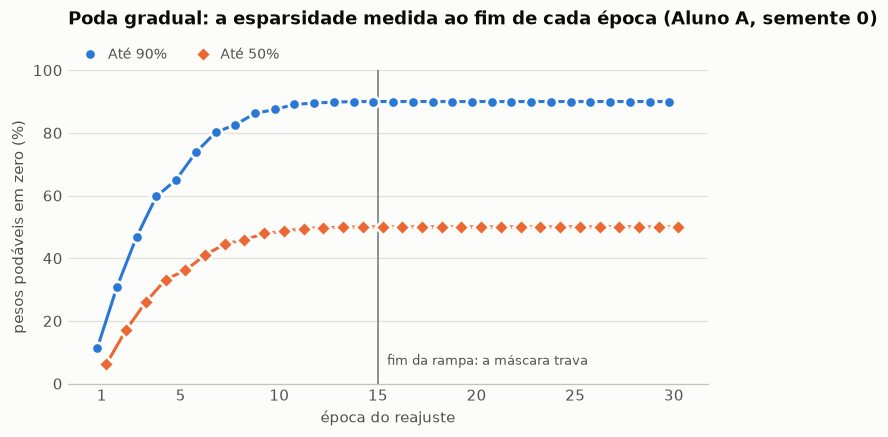

Aluno A (rótulos do Claude Haiku 5.5): cada variante no dev que escolhe a época de parada (média de 3 sementes)


,"época escolhida (sementes 0, 1 e 2)",exact match antes do reajuste,exact match depois,minutos por execução
variante,,,,
"Sem poda, com o mesmo reajuste (controle)","0, 0, 0","61,0","61,0","4,6"
"Magnitude, 30% de uma vez","0, 0, 20","60,6","60,7","4,6"
"Magnitude, 50% de uma vez","0, 0, 5","60,3","60,6","4,6"
"Magnitude, 70% de uma vez","15, 30, 25","58,3","60,6","4,6"
"Magnitude, 90% de uma vez","20, 20, 15","13,1","60,4","4,5"
"Magnitude, 95% de uma vez","30, 30, 30","2,8","58,5","4,6"
"Magnitude, 98% de uma vez","30, 30, 30","1,6","55,0","4,6"
"Magnitude, 30% gradual","20, 30, 30",—,"60,2","4,3"
"Magnitude, 50% gradual","15, 15, 20",—,"60,1","4,5"


In [7]:
todas = [(m, v, e) for m in MODELOS for v in VARIANTES for e in exe[m][v]]

# 1. Os modelos de partida são os que as etapas anteriores entregaram: as respostas deles batem com as gravadas lá
entregues = {m: {p: [carregar_previsoes(Path(MODELOS[m]["previsoes"].format(semente=s, particao=p)))[1] for s in SEMENTES] for p in ("dev", "test")}
             for m in MODELOS}
iguais_as_entregues = min(
    np.mean([a == b for a, b in zip(daqui, de_la)])
    for m in MODELOS for p in ("dev", "test") for daqui, de_la in zip(sem_poda[m][p], entregues[m][p])
)

# 2. O orçamento: toda execução tem as mesmas épocas e a receita de quem treinou o modelo
orcamento_confere = all(e["meta"]["receita"] == etapa7.receita_do_reajuste(m).como_dict() and e["historico"]["epoca"].max() == EPOCAS for m, v, e in todas)
# em quantas execuções o melhor ponto foi o de partida (a "época 0"): o reajuste não acrescentou nada em dev
com_partida = [(m, v, e) for m, v, e in todas if VARIANTES[v]["familia"] not in etapa7.SEM_ANTES]
ficou_na_partida = [(m, v, e) for m, v, e in com_partida if e["meta"]["melhor_epoca"] == 0]

# 3. A esparsidade pedida é a obtida, peso por peso
pesos_por_matriz = {m: poda.por_tensor(de_partida[m].modelo).query("podavel")["pesos"] for m in MODELOS}
zeros_pedidos = lambda m, v: sum(round(VARIANTES[v]["nivel"] / 100 * pesos) for pesos in pesos_por_matriz[m])
zeros_de = lambda e: e["meta"]["contagem"]["podaveis"] - e["meta"]["contagem"]["nao_nulos_podaveis"]
sobra_de_zeros = max(zeros_de(e) - zeros_pedidos(m, v) for m, v, e in todas if v in SOLTAS)
falta_de_zeros = min(zeros_de(e) - zeros_pedidos(m, v) for m, v, e in todas if v in SOLTAS)
esparsidade_confere = 0 <= falta_de_zeros and sobra_de_zeros <= 10   # nenhum zero a menos; um peso que o treino leve a zero por acaso é tolerado
sem_zeros_onde_nao_se_pediu = max(e["meta"]["contagem"]["esparsidade"] for m, v, e in todas if v not in SOLTAS)

# 4. A poda gradual seguiu a curva e só escolheu época depois da rampa
do_principal = etapa7.dados_do_modelo(PRINCIPAL)
passos_ate = np.cumsum(poda.passos_por_epoca(do_principal["treino"], etapa7.receita_do_reajuste(PRINCIPAL)))
fim_da_rampa = passos_ate[RAMPA - 1] // CORTES * CORTES
planejada = lambda s: np.array([poda.esparsidade_cubica(min(p // CORTES * CORTES, fim_da_rampa), fim_da_rampa, s / 100) for p in passos_ate])
desvio_da_curva = max(np.abs(e["historico"]["esparsidade"].to_numpy() - planejada(s)).max() for s in NIVEIS for e in exe[PRINCIPAL][GRADUAL[s]])
gradual_confere = desvio_da_curva < 0.005 and all(e["meta"]["melhor_epoca"] >= RAMPA for m in MODELOS for s in NIVEIS for e in exe[m][GRADUAL[s]])

# 5. Nenhum rótulo humano no reajuste dos alunos: a medida anotada em cada execução bate com a conta refeita contra o professor
dev_do_professor = {}
for m in ALUNOS:
    professor = etapa6.VARIANTES[MODELOS[m]["variante_da_etapa_6"]]["professor"]
    fica = etapa6.dev_do_professor(professor, dev, rotulos["intents"])["valido"].to_numpy()
    dev_do_professor[m] = ([p for p, f in zip(etapa6.previsoes_do_professor(professor, "dev", dev), fica) if f], fica)


def no_dev_de_parada(m, previsoes):
    """As métricas contra quem escolheu a época de parada do modelo, refeitas a partir das respostas gravadas."""
    if m not in ALUNOS:
        return qualidade.avaliar(gabarito["dev"], previsoes)
    do_professor, fica = dev_do_professor[m]
    return qualidade.avaliar(do_professor, [p for p, f in zip(previsoes, fica) if f])


desvio_da_parada = max(abs(no_dev_de_parada(m, e["previsoes"]["dev"])["exact_match"] - e["meta"]["dev"]["exact_match"]) for m, v, e in todas)
sem_humano = desvio_da_parada < 0.005 and all(
    e["meta"]["origem"]["treino"].startswith("rótulos do professor") and e["meta"]["origem"]["dev"].startswith("rótulos do professor")
    for m, v, e in todas if m in ALUNOS
)
# para comparar: a que distância o mesmo exact match ficaria se a conta fosse contra os rótulos humanos (média das execuções de cada aluno)
distancia_para_o_humano = {
    aluno: float(np.mean([abs(qualidade.avaliar(gabarito["dev"], e["previsoes"]["dev"])["exact_match"] - e["meta"]["dev"]["exact_match"])
                          for m, v, e in todas if m == aluno]))
    for aluno in ALUNOS
}

horas = sum(e["meta"]["segundos"] for m, v, e in todas) / 3600
onde_rodou = sorted({e["meta"]["dispositivo"] for m, v, e in todas})

# A esparsidade medida ao fim de cada época, numa execução gradual de cada extremo da grade
historico_de = lambda s: exe[PRINCIPAL][GRADUAL[s]][0]["historico"]
fig, ax = curva(
    {f"Até {s}%": {int(epoca): (100 * valor,) * 3 for epoca, valor in zip(historico_de(s)["epoca"], historico_de(s)["esparsidade"])} for s in (NIVEIS[-1], NIVEIS[1])},
    f"Poda gradual: a esparsidade medida ao fim de cada época ({CURTO[PRINCIPAL]}, semente 0)", "época do reajuste", "pesos podáveis em zero (%)",
    marcas_x=[e for e in range(1, EPOCAS + 1) if e == 1 or e % 5 == 0],
)
ax.set_ylim(0, 100)
ax.axvline(RAMPA, color=visual.TINTA_SUAVE, linewidth=1.2, zorder=0.6)
ax.annotate("fim da rampa: a máscara trava", (RAMPA, 6), xytext=(6, 0), textcoords="offset points", fontsize=8.5, color=visual.TINTA_SECUNDARIA)
visual.salvar(fig, PASTA, "poda_gradual")
plt.show()

epocas = lambda m, v: ", ".join(str(e["meta"]["melhor_epoca"]) for e in exe[m][v])
no_dev = lambda m, v, quando: np.mean([e["meta"][quando]["exact_match"] for e in exe[m][v]])
print(f"{MODELOS[PRINCIPAL]['nome']}: cada variante no dev que escolhe a época de parada (média de 3 sementes)")
pd.DataFrame([
    {
        "variante": VARIANTES[v]["nome"],
        "época escolhida (sementes 0, 1 e 2)": epocas(PRINCIPAL, v),
        "exact match antes do reajuste": pts(no_dev(PRINCIPAL, v, "dev_antes")) if v in COM_ANTES or v == "sem_poda" else "—",
        "exact match depois": pts(no_dev(PRINCIPAL, v, "dev")),
        "minutos por execução": num(np.mean([e["meta"]["segundos"] for e in exe[PRINCIPAL][v]]) / 60, 1),
    }
    for v in VARIANTES
]).set_index("variante")

In [8]:
display(Markdown(f"""
**Leitura.**

- **São {len(todas)} execuções** ({len(MODELOS)} modelos de partida × {len(VARIANTES)} variantes × {len(SEMENTES)} sementes), de {EPOCAS} épocas cada: {num(horas, 1)} horas de processamento somadas, em {lista(onde_rodou)}.
- **Modelos de partida:** as respostas dos modelos sem poda, refeitas aqui, são iguais às gravadas pelas etapas anteriores em pelo menos {pts(iguais_as_entregues, 2)}% dos pedidos de cada conjunto.
- **Orçamento igual para todas:** {"confere" if orcamento_confere else "NÃO confere"}.
- **Quando o reajuste não ajuda, ele não fica.** Em {len(ficou_na_partida)} das {len(com_partida)} execuções em que o ponto de partida concorre, o melhor ponto em `dev` foi o próprio ponto de partida (época 0): o modelo saiu do reajuste como entrou. {("Por variante, no " + minusculo(CURTO[PRINCIPAL]) + ": " + lista([f"{VARIANTES[v]['nome']} ({sum(e['meta']['melhor_epoca'] == 0 for e in exe[PRINCIPAL][v])} de {len(SEMENTES)})" for v in VARIANTES if any(e['meta']['melhor_epoca'] == 0 for e in exe[PRINCIPAL].get(v, []))]) + ".") if any(m == PRINCIPAL for m, v, e in ficou_na_partida) else ""}
- **Esparsidade pedida e obtida:** {"confere" if esparsidade_confere else "NÃO confere"}. Nas {sum(v in SOLTAS for m, v, e in todas)} execuções de pesos soltos, o número de zeros nas matrizes podáveis é o pedido (a maior sobra é de {sobra_de_zeros} pesos). Nas demais, a maior fração de zeros é {pts(sem_zeros_onde_nao_se_pediu, 3)}%.
- **Poda gradual:** {"confere" if gradual_confere else "NÃO confere"}. A esparsidade medida ao fim de cada época segue a curva cúbica (maior desvio: {pts(desvio_da_curva, 2)} ponto), e toda época escolhida é da rampa para a frente (a partir da {RAMPA}ª).
- **Sem rótulo humano no reajuste dos alunos:** {("confere" if sem_humano else "NÃO confere") if ALUNOS else "não se aplica (só o teto foi podado)"}. O exact match anotado em cada execução bate com a conta refeita contra quem escolheu a época de parada (maior diferença: {pts(desvio_da_parada, 2)} ponto){"; contra os rótulos humanos, o mesmo exact match ficaria, em média, a " + lista([f"{pts(d)} pontos ({minusculo(CURTO[m])})" for m, d in distancia_para_o_humano.items()]) + " de distância" if ALUNOS else ""}.
"""))


**Leitura.**

- **São 144 execuções** (3 modelos de partida × 16 variantes × 3 sementes), de 30 épocas cada: 10,4 horas de processamento somadas, em NVIDIA GeForce RTX 3080.
- **Modelos de partida:** as respostas dos modelos sem poda, refeitas aqui, são iguais às gravadas pelas etapas anteriores em pelo menos 100,00% dos pedidos de cada conjunto.
- **Orçamento igual para todas:** confere.
- **Quando o reajuste não ajuda, ele não fica.** Em 17 das 108 execuções em que o ponto de partida concorre, o melhor ponto em `dev` foi o próprio ponto de partida (época 0): o modelo saiu do reajuste como entrou. Por variante, no aluno A: Sem poda, com o mesmo reajuste (controle) (3 de 3), Magnitude, 30% de uma vez (2 de 3), Magnitude, 50% de uma vez (2 de 3) e Sem 30% das linhas da tabela de features (2 de 3).
- **Esparsidade pedida e obtida:** confere. Nas 90 execuções de pesos soltos, o número de zeros nas matrizes podáveis é o pedido (a maior sobra é de 0 pesos). Nas demais, a maior fração de zeros é 0,000%.
- **Poda gradual:** confere. A esparsidade medida ao fim de cada época segue a curva cúbica (maior desvio: 0,00 ponto), e toda época escolhida é da rampa para a frente (a partir da 15ª).
- **Sem rótulo humano no reajuste dos alunos:** confere. O exact match anotado em cada execução bate com a conta refeita contra quem escolheu a época de parada (maior diferença: 0,00 ponto); contra os rótulos humanos, o mesmo exact match ficaria, em média, a 8,4 pontos (aluno A) e 1,3 pontos (aluno B2) de distância.


## 5. Pesos soltos: antes e depois do reajuste

A poda por magnitude feita de uma vez, nos quatro níveis, no teste. Cada nível tem duas medidas: o modelo logo depois do corte (**antes** do reajuste) e o mesmo modelo reajustado com a máscara travada (**depois**). A referência é o modelo sem poda. O ponto de 0% da série "depois" é o controle: o mesmo reajuste, sem tirar nada.

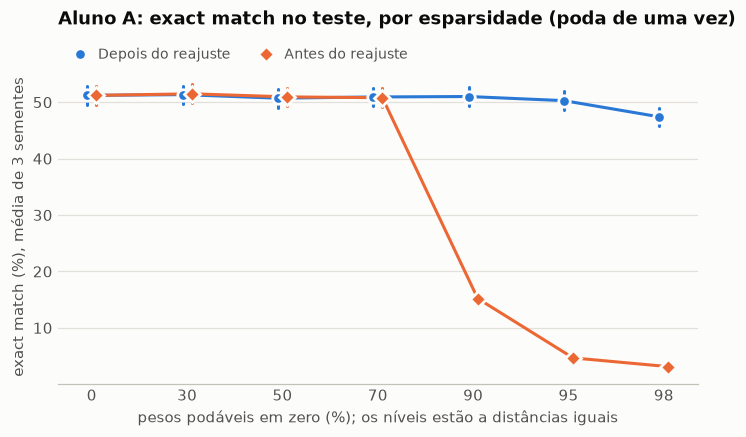

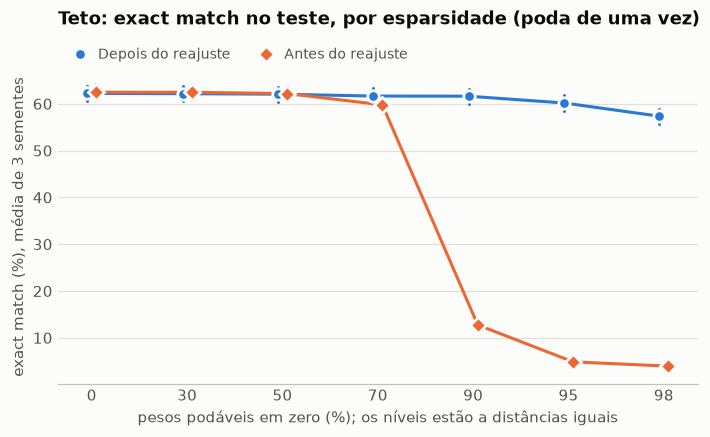

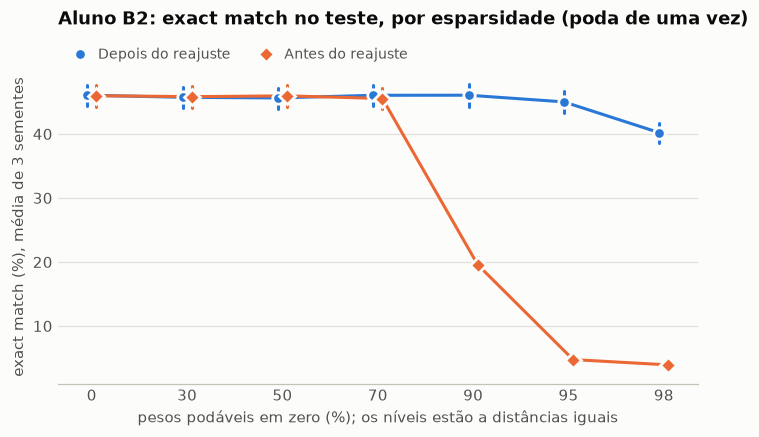

Aluno A (rótulos do Claude Haiku 5.5): exact match no teste, em % (intervalo de 95%); diferenças em pontos percentuais


,antes do reajuste,depois do reajuste,antes − sem poda,depois − sem poda,o que o reajuste recupera (depois − antes)
Sem poda,"51,2 (49,6 a 52,9)",—,—,—,—
"Sem poda, com o mesmo reajuste (controle)",—,"51,2 (49,6 a 52,9)",—,"+0,0 (+0,0 a +0,0)",—
"Magnitude, 30% de uma vez","51,5 (49,8 a 53,1)","51,3 (49,7 a 53,0)","+0,3 (+0,0 a +0,5)","+0,1 (−0,2 a +0,5)","−0,1 (−0,4 a +0,1)"
"Magnitude, 50% de uma vez","50,9 (49,3 a 52,6)","50,7 (49,0 a 52,3)","−0,3 (−0,7 a +0,2)","−0,5 (−0,9 a −0,1)","−0,2 (−0,5 a +0,1)"
"Magnitude, 70% de uma vez","50,8 (49,1 a 52,5)","50,9 (49,3 a 52,6)","−0,4 (−1,1 a +0,2)","−0,3 (−0,8 a +0,2)","+0,1 (−0,5 a +0,8)"
"Magnitude, 90% de uma vez","15,2 (14,2 a 16,2)","51,0 (49,3 a 52,6)","−36,0 (−37,7 a −34,3)","−0,2 (−0,8 a +0,4)","+35,8 (+34,0 a +37,5)"
"Magnitude, 95% de uma vez","4,7 (4,1 a 5,3)","50,3 (48,6 a 52,0)","−46,5 (−48,3 a −44,8)","−0,9 (−1,6 a −0,2)","+45,6 (+43,8 a +47,4)"
"Magnitude, 98% de uma vez","3,1 (2,6 a 3,6)","47,4 (45,8 a 49,0)","−48,1 (−49,8 a −46,3)","−3,8 (−4,7 a −2,9)","+44,3 (+42,6 a +45,9)"


In [9]:
_medidas, _contra, _recupera = {}, {}, {}


def medida(m, v, momento="depois", p="test"):
    """Valor e intervalo de 95% de cada métrica, média de 3 sementes. `v=None` é o modelo sem poda."""
    chave = (m, v, momento, p)
    if chave not in _medidas:
        _medidas[chave] = qualidade.intervalo_do_grupo(gabarito[p], sem_poda[m][p] if v is None else grupo(m, v, p, momento))
    return _medidas[chave]


def contra(m, v, momento="depois", p="test"):
    """Comparação pareada: a variante menos o mesmo modelo sem poda."""
    chave = (m, v, momento, p)
    if chave not in _contra:
        _contra[chave] = qualidade.comparar_grupos(gabarito[p], sem_poda[m][p], grupo(m, v, p, momento))
    return _contra[chave]


def recupera(m, v, p="test"):
    """Comparação pareada: depois do reajuste menos antes."""
    chave = (m, v, p)
    if chave not in _recupera:
        _recupera[chave] = qualidade.comparar_grupos(gabarito[p], grupo(m, v, p, "antes"), grupo(m, v, p, "depois"))
    return _recupera[chave]


def quadro(m, variantes, metrica="exact_match", p="test"):
    """Uma linha por variante: antes, depois, cada um contra o modelo sem poda, e o que o reajuste recupera."""
    linhas = {"Sem poda": {"antes do reajuste": valor_com_intervalo(medida(m, None, p=p).loc[metrica]), "depois do reajuste": "—",
                           "antes − sem poda": "—", "depois − sem poda": "—", "o que o reajuste recupera (depois − antes)": "—"}}
    for v in variantes:
        tem_antes = v in COM_ANTES
        linhas[VARIANTES[v]["nome"]] = {
            "antes do reajuste": valor_com_intervalo(medida(m, v, "antes", p).loc[metrica]) if tem_antes else "—",
            "depois do reajuste": valor_com_intervalo(medida(m, v, "depois", p).loc[metrica]),
            "antes − sem poda": com_intervalo(contra(m, v, "antes", p).loc[metrica]) if tem_antes else "—",
            "depois − sem poda": com_intervalo(contra(m, v, "depois", p).loc[metrica]),
            "o que o reajuste recupera (depois − antes)": com_intervalo(recupera(m, v, p).loc[metrica]) if tem_antes else "—",
        }
    return pd.DataFrame(linhas).T


def pontos_da_curva(m, por_nivel, momento, metrica="exact_match", p="test"):
    """Os pontos de uma série da curva: 0% é o modelo sem poda (antes) ou o controle (depois)."""
    zero = medida(m, None, p=p) if momento == "antes" else medida(m, "sem_poda", "depois", p)
    return {0: trio(zero.loc[metrica]), **{s: trio(medida(m, v, momento, p).loc[metrica]) for s, v in por_nivel.items()}}


for m in MODELOS:
    fig, ax = curva(
        {"Depois do reajuste": pontos_da_curva(m, DE_UMA_VEZ, "depois"), "Antes do reajuste": pontos_da_curva(m, DE_UMA_VEZ, "antes")},
        f"{CURTO[m]}: exact match no teste, por esparsidade (poda de uma vez)", "pesos podáveis em zero (%); os níveis estão a distâncias iguais",
        "exact match (%), média de 3 sementes", niveis=True,
    )
    visual.salvar(fig, PASTA, f"curva_{m}")
    plt.show()

print(f"{MODELOS[PRINCIPAL]['nome']}: exact match no teste, em % (intervalo de 95%); diferenças em pontos percentuais")
quadro(PRINCIPAL, ["sem_poda", *DE_UMA_VEZ.values()])

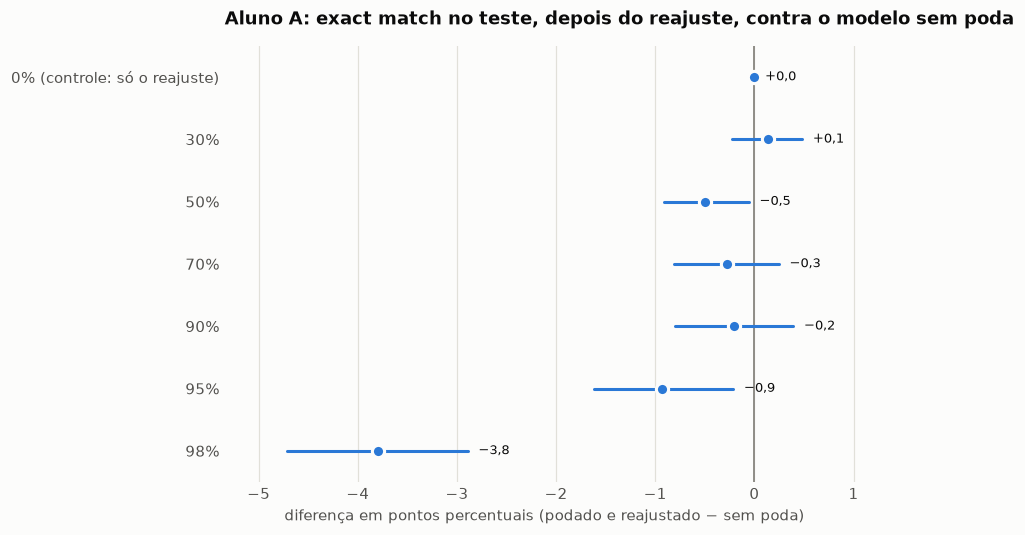

Aluno A (rótulos do Claude Haiku 5.5): as três métricas no teste, depois do reajuste, contra o modelo sem poda (pontos percentuais, intervalo de 95%)


,Acurácia de intenção,F1 de entidades,Exact match
0% (controle),"+0,0 (+0,0 a +0,0)","+0,0 (+0,0 a +0,0)","+0,0 (+0,0 a +0,0)"
30%,"−0,1 (−0,4 a +0,2)","+0,0 (−0,3 a +0,3)","+0,1 (−0,2 a +0,5)"
50%,"−0,3 (−0,6 a +0,0)","−0,3 (−0,7 a +0,1)","−0,5 (−0,9 a −0,1)"
70%,"−0,4 (−0,8 a −0,1)","−0,3 (−0,7 a +0,2)","−0,3 (−0,8 a +0,2)"
90%,"−0,5 (−1,0 a −0,0)","+0,1 (−0,4 a +0,5)","−0,2 (−0,8 a +0,4)"
95%,"−0,8 (−1,4 a −0,2)","−0,5 (−1,0 a +0,0)","−0,9 (−1,6 a −0,2)"
98%,"−2,3 (−3,1 a −1,6)","−1,7 (−2,4 a −1,0)","−3,8 (−4,7 a −2,9)"



Teto (rótulos humanos): exact match no teste


,antes do reajuste,depois do reajuste,antes − sem poda,depois − sem poda,o que o reajuste recupera (depois − antes)
Sem poda,"62,5 (60,8 a 64,1)",—,—,—,—
"Sem poda, com o mesmo reajuste (controle)",—,"62,2 (60,6 a 63,8)",—,"−0,2 (−0,6 a +0,1)",—
"Magnitude, 30% de uma vez","62,5 (60,8 a 64,1)","62,2 (60,5 a 63,8)","−0,0 (−0,3 a +0,3)","−0,3 (−0,7 a +0,1)","−0,3 (−0,6 a +0,0)"
"Magnitude, 50% de uma vez","62,2 (60,5 a 63,8)","62,1 (60,4 a 63,7)","−0,3 (−0,7 a +0,1)","−0,4 (−0,9 a +0,0)","−0,1 (−0,4 a +0,2)"
"Magnitude, 70% de uma vez","59,8 (58,0 a 61,5)","61,7 (60,0 a 63,3)","−2,7 (−3,4 a −2,0)","−0,8 (−1,4 a −0,2)","+1,9 (+1,2 a +2,6)"
"Magnitude, 90% de uma vez","12,8 (11,8 a 13,8)","61,6 (59,9 a 63,2)","−49,7 (−51,4 a −47,8)","−0,9 (−1,5 a −0,2)","+48,9 (+47,0 a +50,6)"
"Magnitude, 95% de uma vez","4,9 (4,1 a 5,6)","60,2 (58,5 a 61,8)","−57,6 (−59,4 a −55,8)","−2,3 (−3,0 a −1,5)","+55,3 (+53,5 a +57,1)"
"Magnitude, 98% de uma vez","3,9 (3,3 a 4,6)","57,4 (55,7 a 58,9)","−58,5 (−60,3 a −56,7)","−5,1 (−6,1 a −4,2)","+53,4 (+51,6 a +55,2)"



Aluno B2 (logits do Qwen3-8B, T = 8): exact match no teste


,antes do reajuste,depois do reajuste,antes − sem poda,depois − sem poda,o que o reajuste recupera (depois − antes)
Sem poda,"46,0 (44,2 a 47,6)",—,—,—,—
"Sem poda, com o mesmo reajuste (controle)",—,"46,1 (44,3 a 47,7)",—,"+0,1 (−0,4 a +0,5)",—
"Magnitude, 30% de uma vez","45,8 (44,1 a 47,5)","45,7 (44,0 a 47,3)","−0,1 (−0,4 a +0,2)","−0,2 (−0,8 a +0,2)","−0,1 (−0,6 a +0,3)"
"Magnitude, 50% de uma vez","46,0 (44,3 a 47,7)","45,6 (43,9 a 47,2)","−0,0 (−0,5 a +0,5)","−0,3 (−0,9 a +0,2)","−0,3 (−0,9 a +0,2)"
"Magnitude, 70% de uma vez","45,5 (43,8 a 47,2)","46,0 (44,3 a 47,7)","−0,4 (−1,2 a +0,3)","+0,1 (−0,5 a +0,6)","+0,5 (−0,1 a +1,2)"
"Magnitude, 90% de uma vez","19,6 (18,4 a 20,7)","46,1 (44,3 a 47,7)","−26,4 (−28,0 a −24,8)","+0,1 (−0,5 a +0,7)","+26,5 (+24,9 a +28,0)"
"Magnitude, 95% de uma vez","4,8 (4,1 a 5,5)","45,0 (43,3 a 46,6)","−41,2 (−43,0 a −39,4)","−1,0 (−1,7 a −0,2)","+40,3 (+38,5 a +42,1)"
"Magnitude, 98% de uma vez","3,9 (3,2 a 4,6)","40,2 (38,5 a 41,8)","−42,1 (−43,8 a −40,2)","−5,8 (−7,0 a −4,7)","+36,3 (+34,5 a +38,1)"


In [10]:
fig, ax = visual.diferencas_com_intervalo(
    {
        "0% (controle: só o reajuste)": trio(contra(PRINCIPAL, "sem_poda").loc["exact_match"], "diferenca"),
        **{f"{s}%": trio(contra(PRINCIPAL, v).loc["exact_match"], "diferenca") for s, v in DE_UMA_VEZ.items()},
    },
    f"{CURTO[PRINCIPAL]}: exact match no teste, depois do reajuste, contra o modelo sem poda", "diferença em pontos percentuais (podado e reajustado − sem poda)",
)
visual.salvar(fig, PASTA, "depois_do_reajuste")
plt.show()

print(f"{MODELOS[PRINCIPAL]['nome']}: as três métricas no teste, depois do reajuste, contra o modelo sem poda (pontos percentuais, intervalo de 95%)")
display(pd.DataFrame({
    ("0% (controle)" if v == "sem_poda" else f"{VARIANTES[v]['nivel']}%"): {qualidade.NOMES[metrica]: com_intervalo(contra(PRINCIPAL, v).loc[metrica]) for metrica in TRES}
    for v in ["sem_poda", *DE_UMA_VEZ.values()]
}).T)

for m in MODELOS:
    if m != PRINCIPAL:
        print(f"\n{MODELOS[m]['nome']}: exact match no teste")
        display(quadro(m, ["sem_poda", *DE_UMA_VEZ.values()]))

In [11]:
def niveis_onde(m, por_nivel, momento, condicao, p="test"):
    return [f"{s}%" for s, v in por_nivel.items() if condicao(contra(m, v, momento, p).loc["exact_match"])]


def leitura_dos_pesos_soltos(m):
    cai_antes = niveis_onde(m, DE_UMA_VEZ, "antes", lambda l: l["ic_max"] < 0)
    cai_depois = niveis_onde(m, DE_UMA_VEZ, "depois", lambda l: l["ic_max"] < 0)
    recuperou = [f"{s}%" for s, v in DE_UMA_VEZ.items() if recupera(m, v).loc["exact_match", "ic_min"] > 0]
    ultimo = DE_UMA_VEZ[TOPO]
    return (
        f"sem reajuste, o exact match fica distinguivelmente abaixo do modelo sem poda em {lista(cai_antes, 'nenhum nível')}; "
        f"com reajuste, em {lista(cai_depois, 'nenhum nível')}. O reajuste melhora o modelo podado, com intervalo todo acima de zero, em {lista(recuperou, 'nenhum nível')}. "
        f"Em {TOPO}%: {com_intervalo(contra(m, ultimo, 'antes').loc['exact_match'])} antes e {com_intervalo(contra(m, ultimo, 'depois').loc['exact_match'])} depois"
    )


controle = contra(PRINCIPAL, "sem_poda")
trinta = DE_UMA_VEZ[NIVEIS[0]]
sem_queda_em_30 = not contra(PRINCIPAL, trinta, "antes").loc["exact_match", "ic_max"] < 0
importa_desde = [s for s, v in DE_UMA_VEZ.items() if recupera(PRINCIPAL, v).loc["exact_match", "ic_min"] > 0]
display(Markdown(f"""
**Leitura (teste, exact match).**

- **{CURTO[PRINCIPAL]}:** {leitura_dos_pesos_soltos(PRINCIPAL)}.
- **O que o reajuste recupera**, nível a nível ({CURTO[PRINCIPAL]}): {"; ".join(f"{s}%: {com_intervalo(recupera(PRINCIPAL, v).loc['exact_match'])}" for s, v in DE_UMA_VEZ.items())}.
- **O controle.** O mesmo reajuste, sem tirar nada, deixa o {minusculo(CURTO[PRINCIPAL])} {posicao(controle.loc['exact_match'])} em relação a si mesmo antes do reajuste ({com_intervalo(controle.loc['exact_match'])} em exact match; {com_intervalo(controle.loc['intent_acc'])} em intenção; {com_intervalo(controle.loc['slot_f1'])} em entidades). É o efeito de {EPOCAS} épocas a mais de treino, sem poda nenhuma.
- **A expectativa do plano** (sem queda para recuperar em {NIVEIS[0]}%; o reajuste importa de 50% para cima): em {NIVEIS[0]}%, sem reajuste, o modelo {"não fica" if sem_queda_em_30 else "fica"} distinguivelmente abaixo do modelo sem poda ({com_intervalo(contra(PRINCIPAL, trinta, 'antes').loc['exact_match'])}); o reajuste faz diferença distinguível {("a partir de " + str(min(importa_desde)) + "%") if importa_desde else "em nenhum nível"}.
""" + "".join(f"- **{CURTO[m]}:** {leitura_dos_pesos_soltos(m)}.\n" for m in MODELOS if m != PRINCIPAL)))


**Leitura (teste, exact match).**

- **Aluno A:** sem reajuste, o exact match fica distinguivelmente abaixo do modelo sem poda em 90%, 95% e 98%; com reajuste, em 50%, 95% e 98%. O reajuste melhora o modelo podado, com intervalo todo acima de zero, em 90%, 95% e 98%. Em 98%: −48,1 (−49,8 a −46,3) antes e −3,8 (−4,7 a −2,9) depois.
- **O que o reajuste recupera**, nível a nível (Aluno A): 30%: −0,1 (−0,4 a +0,1); 50%: −0,2 (−0,5 a +0,1); 70%: +0,1 (−0,5 a +0,8); 90%: +35,8 (+34,0 a +37,5); 95%: +45,6 (+43,8 a +47,4); 98%: +44,3 (+42,6 a +45,9).
- **O controle.** O mesmo reajuste, sem tirar nada, deixa o aluno A sem diferença distinguível em relação a si mesmo antes do reajuste (+0,0 (+0,0 a +0,0) em exact match; +0,0 (+0,0 a +0,0) em intenção; +0,0 (+0,0 a +0,0) em entidades). É o efeito de 30 épocas a mais de treino, sem poda nenhuma.
- **A expectativa do plano** (sem queda para recuperar em 30%; o reajuste importa de 50% para cima): em 30%, sem reajuste, o modelo não fica distinguivelmente abaixo do modelo sem poda (+0,3 (+0,0 a +0,5)); o reajuste faz diferença distinguível a partir de 90%.
- **Teto:** sem reajuste, o exact match fica distinguivelmente abaixo do modelo sem poda em 70%, 90%, 95% e 98%; com reajuste, em 70%, 90%, 95% e 98%. O reajuste melhora o modelo podado, com intervalo todo acima de zero, em 70%, 90%, 95% e 98%. Em 98%: −58,5 (−60,3 a −56,7) antes e −5,1 (−6,1 a −4,2) depois.
- **Aluno B2:** sem reajuste, o exact match fica distinguivelmente abaixo do modelo sem poda em 90%, 95% e 98%; com reajuste, em 95% e 98%. O reajuste melhora o modelo podado, com intervalo todo acima de zero, em 90%, 95% e 98%. Em 98%: −42,1 (−43,8 a −40,2) antes e −5,8 (−7,0 a −4,7) depois.


## 6. De uma vez ou gradual?

As duas formas chegam à mesma esparsidade com o mesmo orçamento de épocas. A comparação é pareada, nível a nível, no teste: gradual menos de uma vez, as duas depois do reajuste.

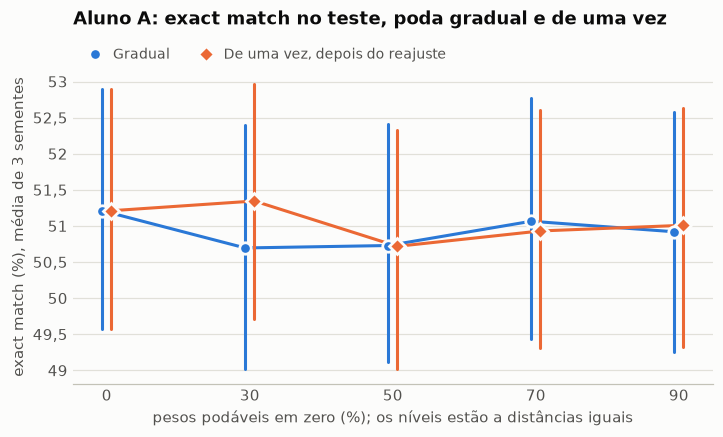

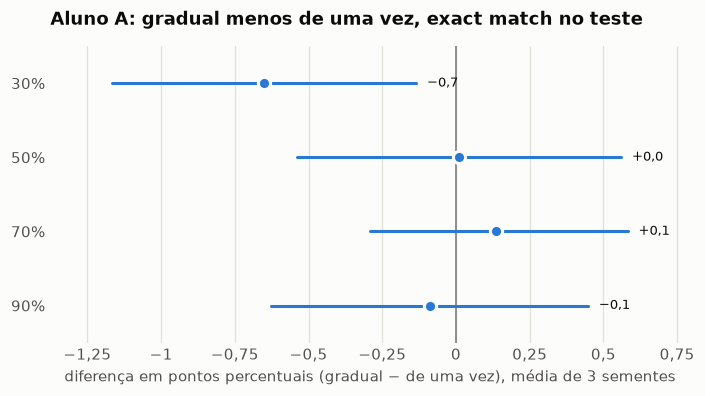

Exact match no teste, em % (intervalo de 95%); diferença em pontos percentuais


de uma vez, depois do reajuste  \
modelo de partida esparsidade                                  
Aluno A           30%                     51,3 (49,7 a 53,0)   
                  50%                     50,7 (49,0 a 52,3)   
                  70%                     50,9 (49,3 a 52,6)   
                  90%                     51,0 (49,3 a 52,6)   
Teto              30%                     62,2 (60,5 a 63,8)   
                  50%                     62,1 (60,4 a 63,7)   
                  70%                     61,7 (60,0 a 63,3)   
                  90%                     61,6 (59,9 a 63,2)   
Aluno B2          30%                     45,7 (44,0 a 47,3)   
                  50%                     45,6 (43,9 a 47,2)   
                  70%                     46,0 (44,3 a 47,7)   
                  90%                     46,1 (44,3 a 47,7)   

                                          gradual gradual − de uma vez  \
modelo de partida esparsidade                                            
Aluno A           30%          50,7 (49,0 a 52,4)   −0,7 (−1,2 a −0,1)   
                  50%          50,7 (49,1 a 52,4)   +0,0 (−0,5 a +0,6)   
                  70%          51,1 (49,4 a 52,8)   +0,1 (−0,3 a +0,6)   
                  90%          50,9 (49,2 a 52,6)   −0,1 (−0,6 a +0,4)   
Teto              30%          61,5 (59,9 a 63,1)   −0,6 (−1,2 a −0,1)   
                  50%          61,7 (60,0 a 63,3)   −0,4 (−1,0 a +0,2)   
                  70%          61,8 (60,1 a 63,4)   +0,1 (−0,4 a +0,6)   
                  90%          61,6 (60,0 a 63,2)   +0,0 (−0,6 a +0,6)   
Aluno B2          30%          45,8 (44,1 a 47,5)   +0,1 (−0,4 a +0,5)   
                  50%          45,7 (44,0 a 47,3)   +0,0 (−0,4 a +0,5)   
                  70%          45,7 (44,0 a 47,4)   −0,3 (−0,8 a +0,1)   
                  90%          46,1 (44,3 a 47,8)   +0,0 (−0,5 a +0,6)   

                               gradual − sem poda  
modelo de partida esparsidade                      
Aluno A           30%          −0,5 (−1,1 a +0,0)  
                  50%          −0,5 (−1,0 a +0,0)  
                  70%          −0,1 (−0,7 a +0,4)  
                  90%          −0,3 (−0,8 a +0,2)  
Teto              30%          −0,9 (−1,6 a −0,3)  
                  50%          −0,8 (−1,4 a −0,2)  
                  70%          −0,7 (−1,3 a −0,0)  
                  90%          −0,9 (−1,4 a −0,2)  
Aluno B2          30%          −0,1 (−0,7 a +0,4)  
                  50%          −0,3 (−0,9 a +0,3)  
                  70%          −0,3 (−0,9 a +0,3)  
                  90%          +0,1 (−0,5 a +0,8)

In [12]:
entre_formas = {
    m: {s: qualidade.comparar_grupos(gabarito["test"], grupo(m, DE_UMA_VEZ[s], "test"), grupo(m, GRADUAL[s], "test")) for s in NIVEIS}
    for m in MODELOS
}
a_cada = etapa7.receita_do_reajuste(PRINCIPAL).avaliar_a_cada
medidas_em_dev = [e for e in range(1, EPOCAS + 1) if e % a_cada == 0 or e == EPOCAS]   # as épocas em que o reajuste é medido em dev
fig, ax = curva(
    {"Gradual": pontos_da_curva(PRINCIPAL, GRADUAL, "depois"),
     "De uma vez, depois do reajuste": pontos_da_curva(PRINCIPAL, {s: DE_UMA_VEZ[s] for s in NIVEIS}, "depois")},
    f"{CURTO[PRINCIPAL]}: exact match no teste, poda gradual e de uma vez", "pesos podáveis em zero (%); os níveis estão a distâncias iguais",
    "exact match (%), média de 3 sementes", niveis=True,
)
visual.salvar(fig, PASTA, "gradual_e_de_uma_vez")
plt.show()

fig, ax = visual.diferencas_com_intervalo(
    {f"{s}%": trio(entre_formas[PRINCIPAL][s].loc["exact_match"], "diferenca") for s in NIVEIS},
    f"{CURTO[PRINCIPAL]}: gradual menos de uma vez, exact match no teste", "diferença em pontos percentuais (gradual − de uma vez), média de 3 sementes",
)
visual.salvar(fig, PASTA, "gradual_menos_de_uma_vez")
plt.show()

print("Exact match no teste, em % (intervalo de 95%); diferença em pontos percentuais")
pd.DataFrame([
    {
        "modelo de partida": CURTO[m], "esparsidade": f"{s}%",
        "de uma vez, depois do reajuste": valor_com_intervalo(medida(m, DE_UMA_VEZ[s]).loc["exact_match"]),
        "gradual": valor_com_intervalo(medida(m, GRADUAL[s]).loc["exact_match"]),
        "gradual − de uma vez": com_intervalo(entre_formas[m][s].loc["exact_match"]),
        "gradual − sem poda": com_intervalo(contra(m, GRADUAL[s]).loc["exact_match"]),
    }
    for m in MODELOS for s in NIVEIS
]).set_index(["modelo de partida", "esparsidade"])

In [13]:
def leitura_das_formas(m):
    melhor = [f"{s}%" for s in NIVEIS if entre_formas[m][s].loc["exact_match", "ic_min"] > 0]
    pior = [f"{s}%" for s in NIVEIS if entre_formas[m][s].loc["exact_match", "ic_max"] < 0]
    if not melhor and not pior:
        return "em nenhum nível dá para distinguir a poda gradual da poda de uma vez"
    return f"a gradual fica acima da poda de uma vez em {lista(melhor, 'nenhum nível')} e abaixo em {lista(pior, 'nenhum nível')}"


display(Markdown(f"""
**Leitura (teste, exact match).**

""" + "".join(
    f"- **{CURTO[m]}:** {leitura_das_formas(m)}. Diferença em {NIVEIS[-1]}%: {com_intervalo(entre_formas[m][NIVEIS[-1]].loc['exact_match'])}.\n" for m in MODELOS
) + f"""- As duas formas gastam as mesmas {EPOCAS} épocas. A gradual usa {RAMPA} delas para chegar à esparsidade final e tem menos candidatos a melhor ponto: {len([e for e in medidas_em_dev if e >= RAMPA])} medidas em `dev`, contra {len(medidas_em_dev) + 1} da poda de uma vez (contando o ponto de partida).
"""))


**Leitura (teste, exact match).**

- **Aluno A:** a gradual fica acima da poda de uma vez em nenhum nível e abaixo em 30%. Diferença em 90%: −0,1 (−0,6 a +0,4).
- **Teto:** a gradual fica acima da poda de uma vez em nenhum nível e abaixo em 30%. Diferença em 90%: +0,0 (−0,6 a +0,6).
- **Aluno B2:** em nenhum nível dá para distinguir a poda gradual da poda de uma vez. Diferença em 90%: +0,0 (−0,5 a +0,6).
- As duas formas gastam as mesmas 30 épocas. A gradual usa 15 delas para chegar à esparsidade final e tem menos candidatos a melhor ponto: 4 medidas em `dev`, contra 7 da poda de uma vez (contando o ponto de partida).


## 7. Peças inteiras

A contraparte estruturada: em vez de zerar pesos soltos, tirar linhas inteiras da tabela de features ou a camada de cima do encoder. A rede que sobra é comum, só que menor. Cada peça tem antes e depois do reajuste, como na seção 5.

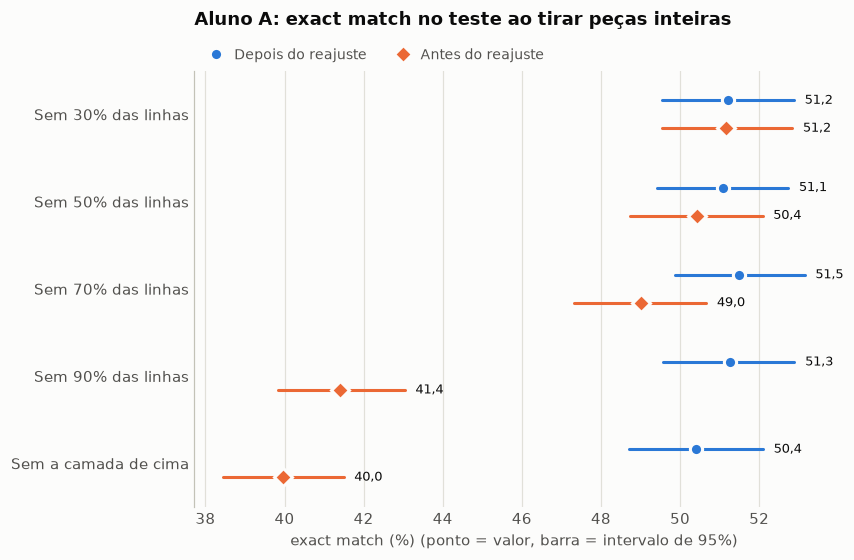

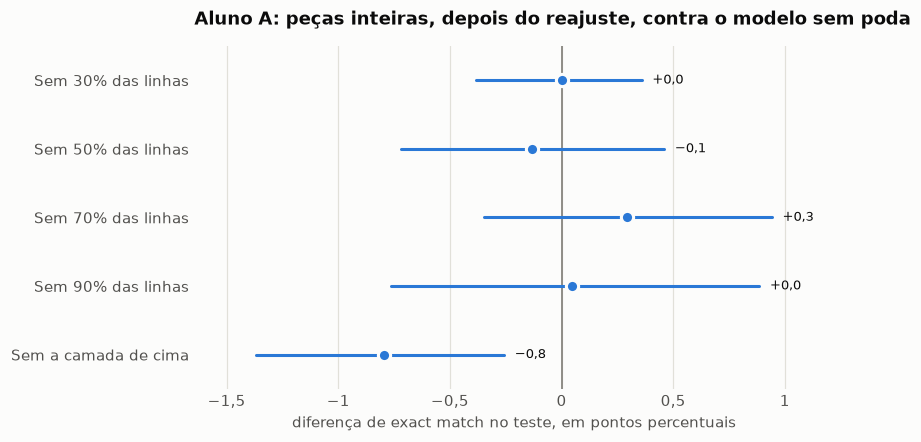

Aluno A (rótulos do Claude Haiku 5.5): exact match no teste, em % (intervalo de 95%). Sem poda: 51,2 (49,6 a 52,9)


,parâmetros,tirado da rede,features no vocabulário,antes do reajuste,depois do reajuste,depois − sem poda,o que o reajuste recupera (depois − antes)
Sem 30% das linhas da tabela de features,3.928.026,"19,8%",17.641,"51,2 (49,6 a 52,8)","51,2 (49,5 a 52,9)","+0,0 (−0,4 a +0,4)","+0,1 (−0,2 a +0,3)"
Sem 50% das linhas da tabela de features,3.282.906,"32,9%",12.601,"50,4 (48,7 a 52,1)","51,1 (49,4 a 52,7)","−0,1 (−0,7 a +0,5)","+0,7 (+0,1 a +1,3)"
Sem 70% das linhas da tabela de features,2.637.786,"46,1%",7.561,"49,0 (47,3 a 50,7)","51,5 (49,9 a 53,1)","+0,3 (−0,3 a +0,9)","+2,5 (+1,7 a +3,3)"
Sem 90% das linhas da tabela de features,1.992.538,"59,3%",2.520,"41,4 (39,8 a 43,0)","51,3 (49,6 a 52,9)","+0,0 (−0,8 a +0,9)","+9,9 (+8,8 a +11,0)"
Sem a camada de cima do encoder,4.105.370,"16,1%",25.202,"40,0 (38,5 a 41,5)","50,4 (48,7 a 52,1)","−0,8 (−1,4 a −0,3)","+10,5 (+9,4 a +11,6)"



Teto (rótulos humanos). Sem poda: 62,5 (60,8 a 64,1)


,parâmetros,tirado da rede,features no vocabulário,antes do reajuste,depois do reajuste,depois − sem poda,o que o reajuste recupera (depois − antes)
Sem 30% das linhas da tabela de features,3.928.026,"19,8%",17.641,"61,8 (60,2 a 63,4)","62,2 (60,6 a 63,8)","−0,3 (−0,9 a +0,3)","+0,4 (−0,2 a +1,0)"
Sem 50% das linhas da tabela de features,3.282.906,"32,9%",12.601,"61,3 (59,7 a 62,8)","62,4 (60,8 a 64,0)","−0,0 (−0,7 a +0,6)","+1,2 (+0,5 a +1,8)"
Sem 70% das linhas da tabela de features,2.637.786,"46,1%",7.561,"59,1 (57,5 a 60,7)","63,1 (61,4 a 64,7)","+0,6 (−0,2 a +1,3)","+4,0 (+3,2 a +4,8)"
Sem 90% das linhas da tabela de features,1.992.538,"59,3%",2.520,"48,4 (46,8 a 50,0)","61,3 (59,6 a 62,9)","−1,2 (−2,1 a −0,3)","+12,9 (+11,7 a +14,1)"
Sem a camada de cima do encoder,4.105.370,"16,1%",25.202,"55,4 (53,6 a 57,0)","60,9 (59,3 a 62,5)","−1,5 (−2,2 a −0,9)","+5,6 (+4,7 a +6,5)"



Aluno B2 (logits do Qwen3-8B, T = 8). Sem poda: 46,0 (44,2 a 47,6)


,parâmetros,tirado da rede,features no vocabulário,antes do reajuste,depois do reajuste,depois − sem poda,o que o reajuste recupera (depois − antes)
Sem 30% das linhas da tabela de features,3.928.026,"19,8%",17.641,"46,0 (44,3 a 47,7)","46,1 (44,4 a 47,8)","+0,1 (−0,4 a +0,8)","+0,1 (−0,4 a +0,7)"
Sem 50% das linhas da tabela de features,3.282.906,"32,9%",12.601,"45,3 (43,5 a 47,0)","46,2 (44,6 a 47,8)","+0,3 (−0,4 a +0,9)","+0,9 (+0,3 a +1,6)"
Sem 70% das linhas da tabela de features,2.637.786,"46,1%",7.561,"43,7 (42,1 a 45,4)","47,0 (45,3 a 48,6)","+1,0 (+0,2 a +1,7)","+3,3 (+2,5 a +4,0)"
Sem 90% das linhas da tabela de features,1.992.538,"59,3%",2.520,"35,7 (34,1 a 37,2)","46,2 (44,5 a 47,9)","+0,2 (−0,7 a +1,2)","+10,5 (+9,5 a +11,6)"
Sem a camada de cima do encoder,4.105.370,"16,1%",25.202,"41,0 (39,3 a 42,6)","45,7 (43,9 a 47,3)","−0,3 (−1,0 a +0,4)","+4,7 (+3,8 a +5,7)"


In [14]:
def quadro_das_pecas(m, p="test"):
    linhas = {}
    de_partida_ = exe[m]["sem_poda"][0]["meta"]["contagem_de_partida"]["parametros"]
    for v in PECAS:
        meta = exe[m][v][0]["meta"]
        linhas[VARIANTES[v]["nome"]] = {
            "parâmetros": n(meta["contagem"]["parametros"]),
            "tirado da rede": pts(1 - meta["contagem"]["parametros"] / de_partida_) + "%",
            "features no vocabulário": n(meta["features"]),
            "antes do reajuste": valor_com_intervalo(medida(m, v, "antes", p).loc["exact_match"]),
            "depois do reajuste": valor_com_intervalo(medida(m, v, "depois", p).loc["exact_match"]),
            "depois − sem poda": com_intervalo(contra(m, v, "depois", p).loc["exact_match"]),
            "o que o reajuste recupera (depois − antes)": com_intervalo(recupera(m, v, p).loc["exact_match"]),
        }
    return pd.DataFrame(linhas).T


CURTO_DA_PECA = {**{v: f"Sem {s}% das linhas" for s, v in LINHAS.items()}, "sem_camada": "Sem a camada de cima"}
fig, ax = visual.pontos_com_intervalo(
    {
        "Depois do reajuste": {CURTO_DA_PECA[v]: trio(medida(PRINCIPAL, v, "depois").loc["exact_match"]) for v in PECAS},
        "Antes do reajuste": {CURTO_DA_PECA[v]: trio(medida(PRINCIPAL, v, "antes").loc["exact_match"]) for v in PECAS},
    },
    f"{CURTO[PRINCIPAL]}: exact match no teste ao tirar peças inteiras", "exact match (%) (ponto = valor, barra = intervalo de 95%)",
)
visual.salvar(fig, PASTA, "pecas_inteiras")
plt.show()

fig, ax = visual.diferencas_com_intervalo(
    {CURTO_DA_PECA[v]: trio(contra(PRINCIPAL, v).loc["exact_match"], "diferenca") for v in PECAS},
    f"{CURTO[PRINCIPAL]}: peças inteiras, depois do reajuste, contra o modelo sem poda", "diferença de exact match no teste, em pontos percentuais",
)
visual.salvar(fig, PASTA, "pecas_inteiras_contra_sem_poda")
plt.show()

sem_poda_no_teste = medida(PRINCIPAL, None).loc["exact_match"]
print(f"{MODELOS[PRINCIPAL]['nome']}: exact match no teste, em % (intervalo de 95%). Sem poda: {valor_com_intervalo(sem_poda_no_teste)}")
display(quadro_das_pecas(PRINCIPAL))
for m in MODELOS:
    if m != PRINCIPAL:
        print(f"\n{MODELOS[m]['nome']}. Sem poda: {valor_com_intervalo(medida(m, None).loc['exact_match'])}")
        display(quadro_das_pecas(m))

In [15]:
def leitura_das_pecas(m):
    cai = [CURTO_DA_PECA[v].lower() for v in PECAS if contra(m, v).loc["exact_match", "ic_max"] < 0]
    aguenta = [CURTO_DA_PECA[v].lower() for v in PECAS if not contra(m, v).loc["exact_match", "ic_max"] < 0]
    camada = contra(m, "sem_camada")
    return (
        f"depois do reajuste, não se distinguem do modelo sem poda em exact match: {lista(aguenta, 'nenhuma peça')}; ficam abaixo: {lista(cai, 'nenhuma')}. "
        f"Sem a camada de cima: {com_intervalo(camada.loc['intent_acc'])} em intenção, {com_intervalo(camada.loc['slot_f1'])} em entidades e {com_intervalo(camada.loc['exact_match'])} em exact match"
    )


maior_corte = LINHAS[NIVEIS[-1]]
meta_do_maior = exe[PRINCIPAL][maior_corte][0]["meta"]
display(Markdown(f"""
**Leitura (teste).**

""" + "".join(f"- **{CURTO[m]}:** {leitura_das_pecas(m)}.\n" for m in MODELOS) + f"""- **Antes do reajuste**, tirar {NIVEIS[-1]}% das linhas deixa o {minusculo(CURTO[PRINCIPAL])} com {pts(medida(PRINCIPAL, maior_corte, 'antes').loc['exact_match', 'valor'])}% de exact match; o reajuste devolve {com_intervalo(recupera(PRINCIPAL, maior_corte).loc['exact_match'])} pontos. O vocabulário cai de {n(n_features)} para {n(meta_do_maior['features'])} features, e a rede, de {n(total)} para {n(meta_do_maior['contagem']['parametros'])} parâmetros.
"""))


**Leitura (teste).**

- **Aluno A:** depois do reajuste, não se distinguem do modelo sem poda em exact match: sem 30% das linhas, sem 50% das linhas, sem 70% das linhas e sem 90% das linhas; ficam abaixo: sem a camada de cima. Sem a camada de cima: −0,5 (−1,0 a −0,1) em intenção, −0,9 (−1,4 a −0,4) em entidades e −0,8 (−1,4 a −0,3) em exact match.
- **Teto:** depois do reajuste, não se distinguem do modelo sem poda em exact match: sem 30% das linhas, sem 50% das linhas e sem 70% das linhas; ficam abaixo: sem 90% das linhas e sem a camada de cima. Sem a camada de cima: −1,0 (−1,5 a −0,5) em intenção, −0,7 (−1,3 a −0,1) em entidades e −1,5 (−2,2 a −0,9) em exact match.
- **Aluno B2:** depois do reajuste, não se distinguem do modelo sem poda em exact match: sem 30% das linhas, sem 50% das linhas, sem 70% das linhas, sem 90% das linhas e sem a camada de cima; ficam abaixo: nenhuma. Sem a camada de cima: −0,5 (−1,0 a −0,1) em intenção, +0,1 (−0,5 a +0,8) em entidades e −0,3 (−1,0 a +0,4) em exact match.
- **Antes do reajuste**, tirar 90% das linhas deixa o aluno A com 41,4% de exact match; o reajuste devolve +9,9 (+8,8 a +11,0) pontos. O vocabulário cai de 25.202 para 2.520 features, e a rede, de 4.895.834 para 1.992.538 parâmetros.


### E se o critério fosse a norma da linha?

A comparação combinada na seção 2, item 9: as mesmas frações de linhas, tiradas pela norma (o critério de Joulin et al.) e pela importância (o critério desta etapa). Sem reajuste e em `dev`, porque é uma conferência da escolha do critério, não um resultado.

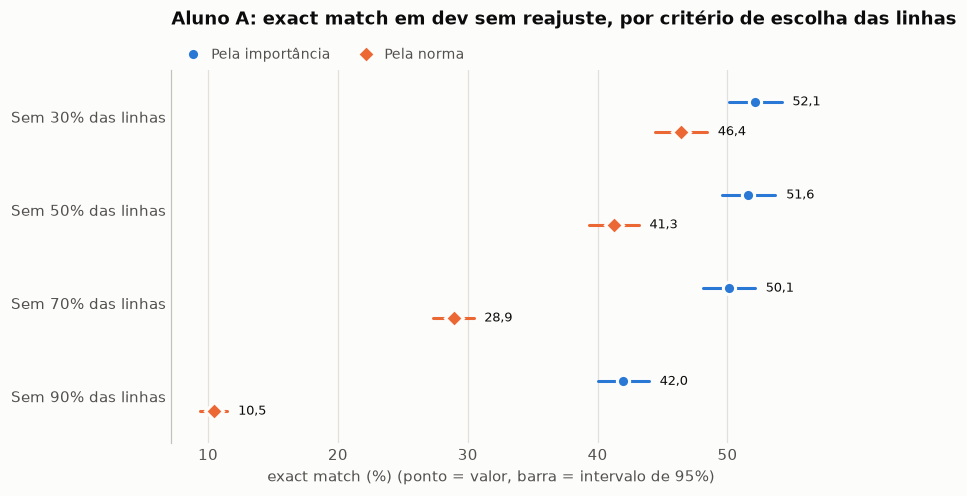


**Leitura (`dev`, sem reajuste; o modelo sem poda faz 52,0%).** Sem 30% das linhas: 46,4% pela norma e 52,1% pela importância (importância − norma: +5,7 (+4,6 a +6,8)). Sem 50% das linhas: 41,3% pela norma e 51,6% pela importância (importância − norma: +10,4 (+9,0 a +11,8)). Sem 70% das linhas: 28,9% pela norma e 50,1% pela importância (importância − norma: +21,2 (+19,5 a +23,0)). Sem 90% das linhas: 10,5% pela norma e 42,0% pela importância (importância − norma: +31,5 (+29,5 a +33,4)).

In [16]:
def sem_linhas_pela_norma(m, semente, s):
    """As respostas em dev do modelo de partida depois de tirar s% das linhas de menor norma, sem reajuste."""
    sistema = SistemaDiet.carregar(MODELOS[m]["pasta"] / f"semente_{semente}", "cpu")
    norma_das_linhas = sistema.modelo.tabela.weight.detach().norm(dim=1)
    return poda.remover_linhas(sistema, poda.linhas_que_ficam(norma_das_linhas, s / 100)).prever(list(dev["utt"]))


pela_norma = {s: [sem_linhas_pela_norma(PRINCIPAL, semente, s) for semente in SEMENTES] for s in NIVEIS}
entre_criterios = {s: qualidade.comparar_grupos(gabarito["dev"], pela_norma[s], grupo(PRINCIPAL, LINHAS[s], "dev", "antes")) for s in NIVEIS}
da_norma = {s: qualidade.intervalo_do_grupo(gabarito["dev"], pela_norma[s]) for s in NIVEIS}

fig, ax = visual.pontos_com_intervalo(
    {
        "Pela importância": {f"Sem {s}% das linhas": trio(medida(PRINCIPAL, LINHAS[s], "antes", "dev").loc["exact_match"]) for s in NIVEIS},
        "Pela norma": {f"Sem {s}% das linhas": trio(da_norma[s].loc["exact_match"]) for s in NIVEIS},
    },
    f"{CURTO[PRINCIPAL]}: exact match em dev sem reajuste, por critério de escolha das linhas", "exact match (%) (ponto = valor, barra = intervalo de 95%)",
)
visual.salvar(fig, PASTA, "criterio_das_linhas")
plt.show()

sem_poda_em_dev = medida(PRINCIPAL, None, p="dev").loc["exact_match", "valor"]
display(Markdown(f"""
**Leitura (`dev`, sem reajuste; o modelo sem poda faz {pts(sem_poda_em_dev)}%).** """ + " ".join(
    f"Sem {s}% das linhas: {pts(da_norma[s].loc['exact_match', 'valor'])}% pela norma e {pts(medida(PRINCIPAL, LINHAS[s], 'antes', 'dev').loc['exact_match', 'valor'])}% pela importância "
    f"(importância − norma: {com_intervalo(entre_criterios[s].loc['exact_match'])})." for s in NIVEIS
)))

## 8. O que muda de verdade: parâmetros, bytes e milissegundos

Até aqui, qualidade. Agora o custo. Tudo nesta seção é medido nos modelos gravados pelas execuções (semente 0): os arquivos são escritos em disco e pesados, e a latência segue o protocolo da Etapa 2 (uma consulta por vez, 1.024 consultas, 1 núcleo de CPU).

- **Arquivo comum:** o formato do projeto (`pesos.pt`, mais o vocabulário e a configuração). Grava todos os pesos, zeros inclusive.
- **Arquivo comum com zip:** os mesmos arquivos, passados por um compressor comum.
- **Arquivo esparso:** o da seção 3.3, que grava só os pesos diferentes de zero.
- **Execução esparsa:** as matrizes do encoder no formato CSR, que só faz as contas dos pesos diferentes de zero (`poda.execucao_esparsa`). Só faz sentido para os pesos soltos.

In [17]:
def medir_eficiencia(m):
    """Tamanho e latência do modelo de partida e de cada variante (semente 0)."""
    textos = list(dev["utt"])
    linhas = {}
    with tempfile.TemporaryDirectory() as temporaria:
        for v in [None, *VARIANTES]:
            pasta = MODELOS[m]["pasta"] / "semente_0" if v is None else exe[m][v][0]["pasta"] / "modelo"
            sistema = SistemaDiet.carregar(pasta, "cpu")
            contagem = poda.contar(sistema.modelo)
            esparso = poda.salvar_esparso(sistema, Path(temporaria) / str(v))
            linhas[v] = {
                "parametros": contagem["parametros"], "nao_nulos": contagem["nao_nulos"],
                "bytes_comum": poda.bytes_do_sistema(pasta),
                "bytes_zip": sum(poda.bytes_com_zip(pasta / arquivo) for arquivo in ("features.json", "config.json", "pesos.pt")),
                "bytes_esparso": poda.bytes_do_sistema(pasta) - (pasta / "pesos.pt").stat().st_size + esparso.stat().st_size,
                "tempos": eficiencia.medir_latencia(sistema, textos),
                "tempos_esparsa": eficiencia.medir_latencia(poda.execucao_esparsa(sistema), textos) if v in SOLTAS else None,
            }
        # o mesmo modelo, medido de novo no fim: quanto a medida de latência varia sozinha
        linhas[None]["tempos_de_novo"] = eficiencia.medir_latencia(SistemaDiet.carregar(MODELOS[m]["pasta"] / "semente_0", "cpu"), textos)
    return linhas


custo = {m: medir_eficiencia(m) for m in MODELOS}
p50 = lambda tempos: eficiencia.resumir_latencia(tempos)["latencia_p50_ms"]
p95 = lambda tempos: eficiencia.resumir_latencia(tempos)["latencia_p95_ms"]

c = custo[PRINCIPAL]
print(f"{MODELOS[PRINCIPAL]['nome']}, semente 0. Tamanhos em MB; latência em ms, 1 núcleo de CPU, uma consulta por vez.")
pd.DataFrame({
    ("Sem poda" if v is None else VARIANTES[v]["nome"]): {
        "parâmetros": n(l["parametros"]),
        "diferentes de zero": n(l["nao_nulos"]),
        "arquivo comum": mb(l["bytes_comum"]),
        "arquivo comum com zip": mb(l["bytes_zip"]),
        "arquivo esparso": mb(l["bytes_esparso"]),
        "latência p50": num(p50(l["tempos"]), 2),
        "latência p95": num(p95(l["tempos"]), 2),
        "latência p50, execução esparsa": num(p50(l["tempos_esparsa"]), 2) if l["tempos_esparsa"] is not None else "—",
    }
    for v, l in c.items()
}).T

Aluno A (rótulos do Claude Haiku 5.5), semente 0. Tamanhos em MB; latência em ms, 1 núcleo de CPU, uma consulta por vez.


,parâmetros,diferentes de zero,arquivo comum,arquivo comum com zip,arquivo esparso,latência p50,latência p95,"latência p50, execução esparsa"
Sem poda,4.895.834,4.889.784,"19,9","18,2","19,9","1,10","1,51",—
"Sem poda, com o mesmo reajuste (controle)",4.895.834,4.889.784,"19,9","18,2","19,9","1,11","1,58",—
"Magnitude, 30% de uma vez",4.895.834,3.440.337,"19,9","14,3","14,7","1,10","1,53","2,12"
"Magnitude, 50% de uma vez",4.895.834,2.474.040,"19,9","11,2","10,8","1,11","1,54","1,72"
"Magnitude, 70% de uma vez",4.895.834,1.507.743,"19,9","7,1","7,0","1,11","1,56","1,37"
"Magnitude, 90% de uma vez",4.895.834,541.447,"19,9","2,9","3,1","1,11","1,54","1,04"
"Magnitude, 95% de uma vez",4.895.834,299.871,"19,9","1,7","2,1","1,13","1,58","0,97"
"Magnitude, 98% de uma vez",4.895.834,154.928,"19,9","0,9","1,6","1,12","1,57","0,85"
"Magnitude, 30% gradual",4.895.834,3.440.337,"19,9","14,1","14,7","1,13","1,60","2,16"
"Magnitude, 50% gradual",4.895.834,2.474.040,"19,9","10,7","10,8","1,13","1,53","1,74"


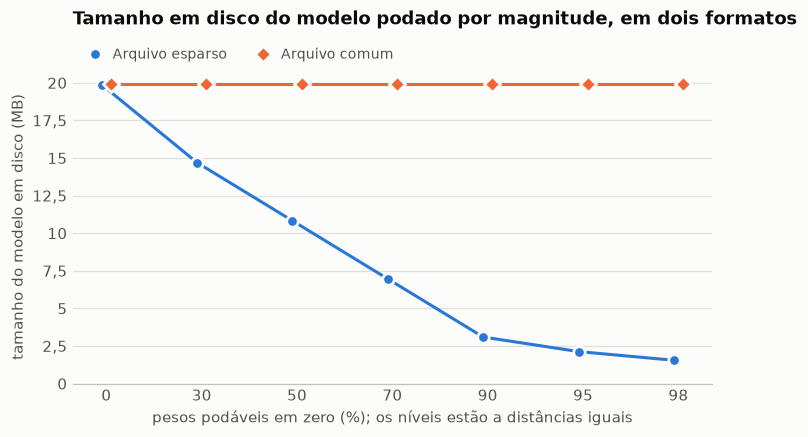

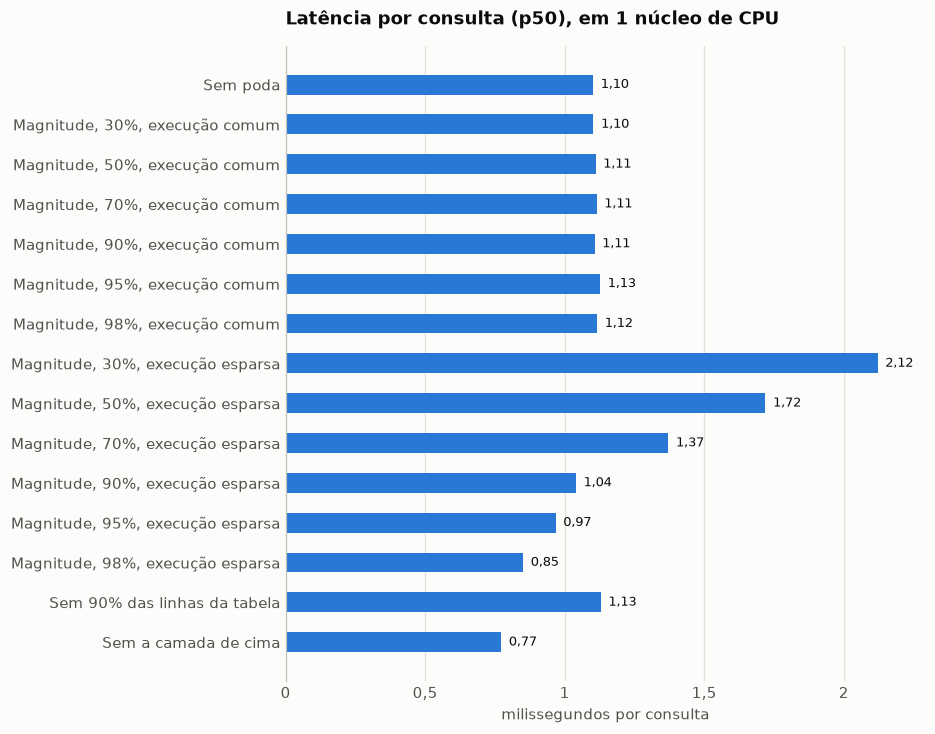

In [18]:
em_mb = lambda v, coluna: (c[v][coluna] / 1e6,) * 3
fig, ax = curva(
    {"Arquivo esparso": {0: em_mb(None, "bytes_esparso"), **{s: em_mb(v, "bytes_esparso") for s, v in DE_UMA_VEZ.items()}},
     "Arquivo comum": {0: em_mb(None, "bytes_comum"), **{s: em_mb(v, "bytes_comum") for s, v in DE_UMA_VEZ.items()}}},
    "Tamanho em disco do modelo podado por magnitude, em dois formatos", "pesos podáveis em zero (%); os níveis estão a distâncias iguais",
    "tamanho do modelo em disco (MB)", niveis=True,
)
ax.set_ylim(bottom=0)
visual.salvar(fig, PASTA, "tamanho_em_disco")
plt.show()

topo = DE_UMA_VEZ[TOPO]
fig, ax = visual.barras_em_ordem(
    {
        "Sem poda": p50(c[None]["tempos"]),
        **{f"Magnitude, {s}%, execução comum": p50(c[v]["tempos"]) for s, v in DE_UMA_VEZ.items()},
        **{f"Magnitude, {s}%, execução esparsa": p50(c[v]["tempos_esparsa"]) for s, v in DE_UMA_VEZ.items()},
        f"Sem {NIVEIS[-1]}% das linhas da tabela": p50(c[LINHAS[NIVEIS[-1]]]["tempos"]),
        "Sem a camada de cima": p50(c["sem_camada"]["tempos"]),
    },
    "Latência por consulta (p50), em 1 núcleo de CPU", "milissegundos por consulta", formato=lambda v: num(v, 2),
)
visual.salvar(fig, PASTA, "latencia")
plt.show()

In [19]:
base = c[None]
ruido = abs(p50(base["tempos_de_novo"]) / p50(base["tempos"]) - 1)
relativo = lambda tempos: p50(tempos) / p50(base["tempos"]) - 1
variacao = lambda x: f"{100 * x:+.0f}%".replace("-", "−")
comum_mexe = max(abs(relativo(c[v]["tempos"])) for v in SOLTAS)
esparsa_ganha = [f"{s}%" for s, v in DE_UMA_VEZ.items() if relativo(c[v]["tempos_esparsa"]) < -max(ruido, 0.03)]
arquivo_igual = all(abs(c[v]["bytes_comum"] - base["bytes_comum"]) < 1024 for v in SOLTAS)
linhas_90, camada = c[LINHAS[NIVEIS[-1]]], c["sem_camada"]
folga = max(2 * ruido, 0.05)                       # abaixo disso, uma diferença de latência não se separa da variação da própria medida
latencia_igual = comum_mexe <= folga
mexe = lambda tempos: "não muda" if abs(relativo(tempos)) <= folga else f"muda {variacao(relativo(tempos))}"
display(Markdown(f"""
**Leitura ({CURTO[PRINCIPAL]}, semente 0).**

- **Parâmetros.** Zerar pesos não tira nenhum da conta comum: o modelo com {TOPO}% de esparsidade continua com {n(c[topo]['parametros'])} parâmetros. Diferentes de zero ficam {n(c[topo]['nao_nulos'])}, que são {pts(c[topo]['nao_nulos'] / base['nao_nulos'])}% dos do modelo sem poda: os {pts(1 - podaveis['pesos'].sum() / total)}% da rede que não entram na poda passam a pesar.
- **Arquivo comum: {"não muda" if arquivo_igual else "MUDA"}.** {mb(c[topo]['bytes_comum'])} MB com {TOPO}% de zeros, {mb(base['bytes_comum'])} MB sem poda. Um zero ocupa os mesmos 4 bytes.
- **Arquivo que aproveita os zeros.** No formato esparso, o modelo vai de {mb(base['bytes_esparso'])} MB para {", ".join(f"{mb(c[v]['bytes_esparso'])} MB em {s}%" for s, v in DE_UMA_VEZ.items())}. Com um zip comum sobre o arquivo de sempre: {", ".join(f"{mb(c[v]['bytes_zip'])} MB em {s}%" for s, v in DE_UMA_VEZ.items())} (sem poda, {mb(base['bytes_zip'])} MB).
- **Latência na execução comum, com os pesos soltos: {"não muda" if latencia_igual else "MUDOU, ao contrário do esperado"}.** A maior variação entre os modelos podados por magnitude e o modelo sem poda é de {pts(comum_mexe, 0)}%; o mesmo modelo sem poda, medido duas vezes nesta sessão, varia {pts(ruido, 0)}%. Um zero entra nas mesmas contas.
- **Latência na execução esparsa**, em relação ao modelo sem poda na execução comum: {"; ".join(f"{s}%: {variacao(relativo(c[v]['tempos_esparsa']))}" for s, v in DE_UMA_VEZ.items())}. {"Ela só compensa em " + lista(esparsa_ganha) + ": pular os zeros tem um custo fixo, que só se paga quando sobram poucos pesos." if esparsa_ganha else "Ela não compensa em nenhum nível: pular os zeros tem um custo fixo, e nesta rede uma consulta faz poucas contas em matrizes pequenas."}
- **Peças inteiras, sem formato especial.** Sem {NIVEIS[-1]}% das linhas da tabela, o arquivo comum cai para {mb(linhas_90['bytes_comum'])} MB ({variacao(linhas_90['bytes_comum'] / base['bytes_comum'] - 1)}) e a latência {mexe(linhas_90['tempos'])} (uma consulta já lia só as linhas dos features do pedido). Sem a camada de cima, o arquivo cai para {mb(camada['bytes_comum'])} MB ({variacao(camada['bytes_comum'] / base['bytes_comum'] - 1)}) e a latência {mexe(camada['tempos'])}.
- **O que não foi medido:** a memória ocupada durante a execução, e outros ambientes de execução além do PyTorch na CPU.
"""))


**Leitura (Aluno A, semente 0).**

- **Parâmetros.** Zerar pesos não tira nenhum da conta comum: o modelo com 98% de esparsidade continua com 4.895.834 parâmetros. Diferentes de zero ficam 154.928, que são 3,2% dos do modelo sem poda: os 1,3% da rede que não entram na poda passam a pesar.
- **Arquivo comum: não muda.** 19,9 MB com 98% de zeros, 19,9 MB sem poda. Um zero ocupa os mesmos 4 bytes.
- **Arquivo que aproveita os zeros.** No formato esparso, o modelo vai de 19,9 MB para 14,7 MB em 30%, 10,8 MB em 50%, 7,0 MB em 70%, 3,1 MB em 90%, 2,1 MB em 95%, 1,6 MB em 98%. Com um zip comum sobre o arquivo de sempre: 14,3 MB em 30%, 11,2 MB em 50%, 7,1 MB em 70%, 2,9 MB em 90%, 1,7 MB em 95%, 0,9 MB em 98% (sem poda, 18,2 MB).
- **Latência na execução comum, com os pesos soltos: não muda.** A maior variação entre os modelos podados por magnitude e o modelo sem poda é de 3%; o mesmo modelo sem poda, medido duas vezes nesta sessão, varia 3%. Um zero entra nas mesmas contas.
- **Latência na execução esparsa**, em relação ao modelo sem poda na execução comum: 30%: +93%; 50%: +56%; 70%: +24%; 90%: −6%; 95%: −12%; 98%: −23%. Ela só compensa em 90%, 95% e 98%: pular os zeros tem um custo fixo, que só se paga quando sobram poucos pesos.
- **Peças inteiras, sem formato especial.** Sem 90% das linhas da tabela, o arquivo comum cai para 8,1 MB (−60%) e a latência não muda (uma consulta já lia só as linhas dos features do pedido). Sem a camada de cima, o arquivo cai para 16,8 MB (−16%) e a latência muda −30%.
- **O que não foi medido:** a memória ocupada durante a execução, e outros ambientes de execução além do PyTorch na CPU.


## 9. O que segue para a quantização

A regra da seção 2, item 11, aplicada a cada modelo de partida em `dev`, com os rótulos humanos.

In [20]:
decisoes = {}
for m in MODELOS:
    candidatos = {
        v: {"em_dev": grupo(m, v, "dev"), "nao_nulos": round(np.mean([e["meta"]["contagem"]["nao_nulos"] for e in exe[m][v]])),
            "bytes": custo[m][v]["bytes_comum"]}   # o arquivo comum, medido na seção 8
        for v in PODADAS
    }
    decisoes[m] = etapa7.quem_segue(gabarito["dev"], sem_poda[m]["dev"], candidatos)

for m in MODELOS:
    tabela = decisoes[m]["tabela"]
    print(f"{MODELOS[m]['nome']}: exact match em dev depois do reajuste, contra o modelo sem poda ({pts(tabela['sem_poda'].iloc[0])}%)")
    display(pd.DataFrame({
        "variante": [VARIANTES[v]["nome"] for v in tabela.index],
        "exact match em dev": tabela["podado"].map(pts).to_numpy(),
        "diferença para o modelo sem poda (intervalo de 95%)": [com_intervalo(l) for _, l in tabela.iterrows()],
        "diferentes de zero": tabela["nao_nulos"].map(n).to_numpy(),
        "arquivo comum (MB)": tabela["bytes"].map(mb).to_numpy(),
        "passa": tabela["passa"].map({True: "sim", False: "não"}).to_numpy(),
        "segue": ["principal" if v == decisoes[m]["principal"] else "secundária" if v == decisoes[m]["secundaria"] else "" for v in tabela.index],
    }).set_index("variante"))

Aluno A (rótulos do Claude Haiku 5.5): exact match em dev depois do reajuste, contra o modelo sem poda (52,0%)


,exact match em dev,diferença para o modelo sem poda (intervalo de 95%),diferentes de zero,arquivo comum (MB),passa,segue
variante,,,,,,
"Magnitude, 30% de uma vez","52,0","−0,1 (−0,5 a +0,3)",3.440.337,"19,9",sim,
"Magnitude, 50% de uma vez","51,9","−0,2 (−0,7 a +0,3)",2.474.040,"19,9",sim,
"Magnitude, 70% de uma vez","51,6","−0,4 (−1,0 a +0,2)",1.507.743,"19,9",sim,
"Magnitude, 90% de uma vez","52,5","+0,4 (−0,3 a +1,1)",541.447,"19,9",sim,
"Magnitude, 95% de uma vez","51,3","−0,8 (−1,6 a +0,0)",299.871,"19,9",sim,secundária
"Magnitude, 98% de uma vez","48,9","−3,1 (−4,3 a −2,0)",154.928,"19,9",não,
"Magnitude, 30% gradual","51,5","−0,5 (−1,1 a +0,1)",3.440.337,"19,9",sim,
"Magnitude, 50% gradual","52,0","−0,0 (−0,6 a +0,5)",2.474.040,"19,9",sim,
"Magnitude, 70% gradual","51,6","−0,5 (−1,1 a +0,2)",1.507.743,"19,9",sim,


Teto (rótulos humanos): exact match em dev depois do reajuste, contra o modelo sem poda (62,6%)


,exact match em dev,diferença para o modelo sem poda (intervalo de 95%),diferentes de zero,arquivo comum (MB),passa,segue
variante,,,,,,
"Magnitude, 30% de uma vez","62,5","−0,1 (−0,6 a +0,4)",3.440.337,"19,9",sim,
"Magnitude, 50% de uma vez","62,5","−0,1 (−0,7 a +0,4)",2.474.040,"19,9",sim,
"Magnitude, 70% de uma vez","62,2","−0,4 (−1,1 a +0,3)",1.507.743,"19,9",sim,
"Magnitude, 90% de uma vez","62,0","−0,6 (−1,3 a +0,2)",541.447,"19,9",sim,secundária
"Magnitude, 95% de uma vez","61,1","−1,5 (−2,4 a −0,7)",299.871,"19,9",não,
"Magnitude, 98% de uma vez","57,7","−4,9 (−6,0 a −3,7)",154.928,"19,9",não,
"Magnitude, 30% gradual","62,1","−0,5 (−1,2 a +0,2)",3.440.337,"19,9",sim,
"Magnitude, 50% gradual","62,2","−0,4 (−1,2 a +0,3)",2.474.040,"19,9",sim,
"Magnitude, 70% gradual","62,1","−0,5 (−1,2 a +0,3)",1.507.743,"19,9",sim,


Aluno B2 (logits do Qwen3-8B, T = 8): exact match em dev depois do reajuste, contra o modelo sem poda (46,9%)


,exact match em dev,diferença para o modelo sem poda (intervalo de 95%),diferentes de zero,arquivo comum (MB),passa,segue
variante,,,,,,
"Magnitude, 30% de uma vez","46,6","−0,3 (−0,8 a +0,3)",3.440.337,"19,9",sim,
"Magnitude, 50% de uma vez","47,2","+0,3 (−0,3 a +1,0)",2.474.040,"19,9",sim,
"Magnitude, 70% de uma vez","47,2","+0,3 (−0,3 a +0,9)",1.507.743,"19,9",sim,
"Magnitude, 90% de uma vez","46,9","−0,0 (−0,8 a +0,7)",541.447,"19,9",sim,
"Magnitude, 95% de uma vez","45,8","−1,1 (−2,0 a −0,1)",299.871,"19,9",não,
"Magnitude, 98% de uma vez","41,5","−5,4 (−6,7 a −4,1)",154.928,"19,9",não,
"Magnitude, 30% gradual","46,7","−0,2 (−0,8 a +0,4)",3.440.337,"19,9",sim,
"Magnitude, 50% gradual","47,0","+0,1 (−0,6 a +0,7)",2.474.040,"19,9",sim,
"Magnitude, 70% gradual","46,7","−0,2 (−0,9 a +0,5)",1.507.743,"19,9",sim,


In [21]:
def descricao(m, v):
    l = decisoes[m]["tabela"].loc[v]
    return (f"**{minusculo(VARIANTES[v]['nome'])}** (arquivo comum de {mb(l['bytes'])} MB, {n(l['nao_nulos'])} parâmetros diferentes de zero; "
            f"em `dev`, {com_intervalo(l)} de exact match em relação ao modelo sem poda)")


def frase_da_decisao(m):
    d = decisoes[m]
    principal = (f"a principal é {descricao(m, d['principal'])}" if d["principal"]
                 else f"nenhuma peça inteira passa: a principal é o **modelo sem poda** (arquivo comum de {mb(custo[m][None]['bytes_comum'])} MB)")
    secundaria = (f"a secundária é {descricao(m, d['secundaria'])}" if d["secundaria"] else "nenhuma variante de pesos soltos passa: não há secundária")
    return principal + "; " + secundaria


def descartadas(m):
    """O que a regra deixou de fora, em uma frase: quem não passou e quem passou mas perdeu para outra."""
    tabela, d = decisoes[m]["tabela"], decisoes[m]
    nao_passam = [minusculo(VARIANTES[v]["nome"]) for v in tabela.index if not tabela.loc[v, "passa"]]
    passam_e_ficam = [minusculo(VARIANTES[v]["nome"]) for v in tabela.index if tabela.loc[v, "passa"] and v not in d["seguem"]]
    return (f"não passam {len(nao_passam)} de {len(tabela)} variantes ({lista(nao_passam, 'nenhuma')}); "
            f"passam e ficam de fora, por haver outra menor ou mais esparsa, {len(passam_e_ficam)} ({lista(passam_e_ficam, 'nenhuma')})")


final = decisoes[PRINCIPAL]["principal"]
display(Markdown(f"""
**Decisão.**

""" + "".join(f"- **{CURTO[m]}:** {frase_da_decisao(m)}.\n" for m in MODELOS) + f"""
**O que a regra descartou.**

""" + "".join(f"- **{CURTO[m]}:** {descartadas(m)}.\n" for m in MODELOS) + f"""
A Etapa 8 parte do **{minusculo(CURTO[PRINCIPAL])}**{", na variante " + minusculo(VARIANTES[final]["nome"]) if final else ", sem poda"}. A secundária, de pesos soltos, tem o mesmo arquivo comum do modelo sem poda: só fica menor num formato que aproveite os zeros (seção 8), e a Etapa 8 precisa conferir que os zeros continuam zeros depois de quantizar.
"""))


**Decisão.**

- **Aluno A:** a principal é **sem 90% das linhas da tabela de features** (arquivo comum de 8,1 MB, 1.986.488 parâmetros diferentes de zero; em `dev`, −0,4 (−1,4 a +0,6) de exact match em relação ao modelo sem poda); a secundária é **magnitude, 95% de uma vez** (arquivo comum de 19,9 MB, 299.871 parâmetros diferentes de zero; em `dev`, −0,8 (−1,6 a +0,0) de exact match em relação ao modelo sem poda).
- **Teto:** a principal é **sem 90% das linhas da tabela de features** (arquivo comum de 8,1 MB, 1.986.488 parâmetros diferentes de zero; em `dev`, −0,8 (−2,0 a +0,2) de exact match em relação ao modelo sem poda); a secundária é **magnitude, 90% de uma vez** (arquivo comum de 19,9 MB, 541.447 parâmetros diferentes de zero; em `dev`, −0,6 (−1,3 a +0,2) de exact match em relação ao modelo sem poda).
- **Aluno B2:** a principal é **sem 90% das linhas da tabela de features** (arquivo comum de 8,1 MB, 1.986.488 parâmetros diferentes de zero; em `dev`, −0,0 (−1,1 a +1,0) de exact match em relação ao modelo sem poda); a secundária é **magnitude, 90% gradual** (arquivo comum de 19,9 MB, 541.447 parâmetros diferentes de zero; em `dev`, +0,1 (−0,7 a +0,8) de exact match em relação ao modelo sem poda).

**O que a regra descartou.**

- **Aluno A:** não passam 2 de 15 variantes (magnitude, 98% de uma vez e sem a camada de cima do encoder); passam e ficam de fora, por haver outra menor ou mais esparsa, 11 (magnitude, 30% de uma vez, magnitude, 50% de uma vez, magnitude, 70% de uma vez, magnitude, 90% de uma vez, magnitude, 30% gradual, magnitude, 50% gradual, magnitude, 70% gradual, magnitude, 90% gradual, sem 30% das linhas da tabela de features, sem 50% das linhas da tabela de features e sem 70% das linhas da tabela de features).
- **Teto:** não passam 3 de 15 variantes (magnitude, 95% de uma vez, magnitude, 98% de uma vez e sem a camada de cima do encoder); passam e ficam de fora, por haver outra menor ou mais esparsa, 10 (magnitude, 30% de uma vez, magnitude, 50% de uma vez, magnitude, 70% de uma vez, magnitude, 30% gradual, magnitude, 50% gradual, magnitude, 70% gradual, magnitude, 90% gradual, sem 30% das linhas da tabela de features, sem 50% das linhas da tabela de features e sem 70% das linhas da tabela de features).
- **Aluno B2:** não passam 2 de 15 variantes (magnitude, 95% de uma vez e magnitude, 98% de uma vez); passam e ficam de fora, por haver outra menor ou mais esparsa, 11 (magnitude, 30% de uma vez, magnitude, 50% de uma vez, magnitude, 70% de uma vez, magnitude, 90% de uma vez, magnitude, 30% gradual, magnitude, 50% gradual, magnitude, 70% gradual, sem 30% das linhas da tabela de features, sem 50% das linhas da tabela de features, sem 70% das linhas da tabela de features e sem a camada de cima do encoder).

A Etapa 8 parte do **aluno A**, na variante sem 90% das linhas da tabela de features. A secundária, de pesos soltos, tem o mesmo arquivo comum do modelo sem poda: só fica menor num formato que aproveite os zeros (seção 8), e a Etapa 8 precisa conferir que os zeros continuam zeros depois de quantizar.


## 10. Entrega

Vão para a entrega os modelos que seguem (3 sementes cada), as respostas deles, a tabela de resultados de todas as variantes, cada comparação e a decisão.

- Em `modelos/`, cada pasta é uma pasta comum de `SistemaDiet`, com três arquivos: os pesos densos (com zeros no lugar dos pesos podados, ou a rede menor), o vocabulário e a configuração. É o que a Etapa 8 lê.
- Em `modelos_esparsos/`, os modelos de pesos soltos gravados no arquivo esparso da seção 3.3.

In [22]:
relativo_a_raiz = lambda caminho: str(Path(caminho).relative_to(RAIZ))

# 1. Os modelos que seguem, com as respostas e os históricos
for antiga in ("modelos", "modelos_esparsos", "previsoes", "historicos"):
    if (PASTA / antiga).exists():
        shutil.rmtree(PASTA / antiga)     # só fica o que é da decisão e das execuções atuais
(PASTA / "historicos").mkdir()
PASTA_COMUM = ["config.json", "features.json", "pesos.pt"]
reproduz, mantem_os_zeros, pasta_comum = [], [], []
for m in MODELOS:
    for v in decisoes[m]["seguem"]:
        for i, semente in enumerate(SEMENTES):
            destino = PASTA / "modelos" / m / v / f"semente_{semente}"
            shutil.copytree(exe[m][v][i]["pasta"] / "modelo", destino)
            pasta_comum.append(sorted(arquivo.name for arquivo in destino.iterdir()) == PASTA_COMUM)
            entregue = SistemaDiet.carregar(destino, "cpu")
            reproduz.append(entregue.prever(list(teste["utt"])) == exe[m][v][i]["previsoes"]["test"])
            if v in SOLTAS:
                esparso = PASTA / "modelos_esparsos" / m / v / f"semente_{semente}"
                esparso.mkdir(parents=True)
                for arquivo in ("config.json", "features.json"):
                    shutil.copy(destino / arquivo, esparso / arquivo)
                poda.salvar_esparso(entregue, esparso)
                do_esparso = poda.carregar_esparso(esparso)
                reproduz.append(do_esparso.prever(list(teste["utt"])) == exe[m][v][i]["previsoes"]["test"])
                mantem_os_zeros.append(zeros_de({"meta": {"contagem": poda.contar(do_esparso.modelo)}}) == zeros_de(exe[m][v][i]))
            for particao, ids in (("dev", dev["id"]), ("test", teste["id"])):
                salvar_previsoes(PASTA / "previsoes" / f"{m}__{v}_semente_{semente}_{particao}.parquet", ids, exe[m][v][i]["previsoes"][particao])
    for v in VARIANTES:
        for semente, e in zip(SEMENTES, exe[m][v]):
            e["historico"].to_csv(PASTA / "historicos" / f"{m}__{v}_semente_{semente}.csv", index=False)

# 2. A tabela de resultados: o modelo sem poda e cada variante, antes e depois do reajuste, em dev e no teste
linhas_resultado = []
for m in MODELOS:
    de_onde = minusculo(MODELOS[m]["nome"])
    for particao in ("dev", "test"):
        linhas_resultado.append(resultados.registrar_grupo(
            f"DIET do zero, {de_onde}, sem poda, média de {len(SEMENTES)} sementes", particao, gabarito[particao], sem_poda[m][particao],
            tempos_ms=custo[m][None]["tempos"], parametros=custo[m][None]["parametros"], bytes_em_disco=custo[m][None]["bytes_comum"], threads=1,
            modelo=m, variante="(sem poda)", momento="de partida", nao_nulos=custo[m][None]["nao_nulos"],
            bytes_com_zip=custo[m][None]["bytes_zip"], bytes_esparso=custo[m][None]["bytes_esparso"],
        ))
        for v in VARIANTES:
            for momento in (["antes do reajuste"] if v in COM_ANTES else []) + ["depois do reajuste"]:
                depois = momento == "depois do reajuste"
                l = custo[m][v]
                linhas_resultado.append(resultados.registrar_grupo(
                    f"DIET do zero, {de_onde}, {minusculo(VARIANTES[v]['nome'])}, {momento}, média de {len(SEMENTES)} sementes", particao, gabarito[particao],
                    grupo(m, v, particao, "depois" if depois else "antes"),
                    tempos_ms=l["tempos"] if depois else None, parametros=l["parametros"], bytes_em_disco=l["bytes_comum"], threads=1,
                    modelo=m, variante=v, momento=momento, nao_nulos=l["nao_nulos"] if depois else None,
                    bytes_com_zip=l["bytes_zip"] if depois else None, bytes_esparso=l["bytes_esparso"] if depois else None,
                    latencia_p50_ms_execucao_esparsa=p50(l["tempos_esparsa"]) if depois and l["tempos_esparsa"] is not None else None,
                ))
resultados.salvar(linhas_resultado, PASTA)

# 3. As comparações pareadas: cada variante contra o modelo sem poda (dev e teste), o que o reajuste recupera e gradual contra de uma vez (teste)
comparacoes = {}
for m in MODELOS:
    for v in VARIANTES:
        for particao in ("dev", "test"):
            comparacoes[(m, v, "depois − sem poda", particao)] = contra(m, v, "depois", particao)
        if v in COM_ANTES:
            comparacoes[(m, v, "antes − sem poda", "test")] = contra(m, v, "antes", "test")
            comparacoes[(m, v, "depois − antes", "test")] = recupera(m, v)
    for s in NIVEIS:
        comparacoes[(m, GRADUAL[s], "gradual − de uma vez", "test")] = entre_formas[m][s]
pd.concat({chave: t.loc[list(qualidade.METRICAS)] for chave, t in comparacoes.items()},
          names=["modelo", "variante", "comparacao", "particao", "metrica"]).to_csv(PASTA / "comparacoes.csv")

# 4. O custo de cada variante (semente 0)
pd.DataFrame([
    {"modelo": m, "variante": v or "(sem poda)", "parametros": l["parametros"], "nao_nulos": l["nao_nulos"], "bytes_comum": l["bytes_comum"],
     "bytes_com_zip": l["bytes_zip"], "bytes_esparso": l["bytes_esparso"], **eficiencia.resumir_latencia(l["tempos"]),
     "latencia_p50_ms_execucao_esparsa": p50(l["tempos_esparsa"]) if l["tempos_esparsa"] is not None else None, **eficiencia.ambiente()}
    for m in MODELOS for v, l in custo[m].items()
]).to_csv(PASTA / "eficiencia.csv", index=False)

# 5. A tabela principal: cada variante de cada modelo de partida, no teste, com a qualidade e o custo lado a lado
def linha_principal(m, v):
    """`v=None` é o modelo sem poda. Qualidade no teste (média de 3 sementes), custo medido na semente 0."""
    l, depois = custo[m][v], medida(m, v)
    d = decisoes[m]
    linha = {
        "modelo": m, "variante": v or "(sem poda)", "familia": VARIANTES[v]["familia"] if v else "sem poda", "nivel": VARIANTES[v]["nivel"] if v else 0,
        **{metrica: depois.loc[metrica, "valor"] for metrica in qualidade.METRICAS},
        "exact_match_ic_min": depois.loc["exact_match", "ic_min"], "exact_match_ic_max": depois.loc["exact_match", "ic_max"],
        "exact_match_antes_do_reajuste": medida(m, v, "antes").loc["exact_match", "valor"] if v in COM_ANTES else None,
        **{f"exact_match_menos_sem_poda_{k}": contra(m, v).loc["exact_match", k] if v else None for k in ("diferenca", "ic_min", "ic_max")},
        "parametros": l["parametros"], "nao_nulos": l["nao_nulos"], "bytes_comum": l["bytes_comum"], "bytes_com_zip": l["bytes_zip"],
        "bytes_esparso": l["bytes_esparso"], "latencia_p50_ms": p50(l["tempos"]),
        "latencia_p50_ms_execucao_esparsa": p50(l["tempos_esparsa"]) if l["tempos_esparsa"] is not None else None,
        "passa_em_dev": bool(d["tabela"].loc[v, "passa"]) if v in d["tabela"].index else None,
        "papel": "principal" if v == d["principal"] else "secundária" if v and v == d["secundaria"] else "",
    }
    return linha


tabela_principal = pd.DataFrame([linha_principal(m, v) for m in MODELOS for v in [None, *VARIANTES]])
tabela_principal.to_csv(PASTA / "tabela_principal.csv", index=False)

# 6. A decisão: é este arquivo que a Etapa 8 lê
pastas_por_semente = lambda raiz: {str(semente): relativo_a_raiz(Path(raiz) / f"semente_{semente}") for semente in SEMENTES}
tamanhos = lambda l: {"arquivo_comum": l["bytes_comum"], "arquivo_comum_com_zip": l["bytes_zip"], "arquivo_esparso": l["bytes_esparso"]}


def ficha(m, v, papel):
    l, d = custo[m][v], decisoes[m]["tabela"].loc[v]
    soltos = v in SOLTAS
    raiz = PASTA / "modelos" / m / v
    return {
        "variante": v, "papel": papel, "nome": VARIANTES[v]["nome"], "familia": VARIANTES[v]["familia"], "nivel": VARIANTES[v]["nivel"],
        "modelos": relativo_a_raiz(raiz), "pastas_por_semente": pastas_por_semente(raiz), "sementes": list(SEMENTES),
        **({"modelos_esparsos": relativo_a_raiz(PASTA / "modelos_esparsos" / m / v)} if soltos else {}),
        "parametros": l["parametros"], "nao_nulos": l["nao_nulos"], "bytes": tamanhos(l), "latencia_p50_ms": p50(l["tempos"]),
        "exact_match_em_dev": float(d["podado"]), "diferenca_para_sem_poda_em_dev": {k: float(d[k]) for k in ("diferenca", "ic_min", "ic_max")},
        "como_ler": ("SistemaDiet.carregar(pasta da semente). Os pesos podados estão gravados como zeros em pesos.pt; a máscara é lida deles "
                     "(poda.mascaras_dos_zeros). A cópia em modelos_esparsos é lida por poda.carregar_esparso." if soltos
                     else "SistemaDiet.carregar(pasta da semente). É uma rede comum, menor."),
    }


decisao = {
    "etapa": "07_poda",
    "gerado_em": date.today().isoformat(),
    "regra": ("em dev, com rótulos humanos: passa a variante cujo exact match depois do reajuste não é distinguivelmente menor que o do modelo sem poda "
              "(IC95 da diferença pareada, média de 3 sementes). A principal é a que passa com o menor arquivo comum (denso); se nenhuma peça inteira passa, "
              "é o modelo sem poda. A secundária é a de pesos soltos que passa com a maior esparsidade."),
    "como_ler": ("Em cada modelo de partida: `principal` e `secundaria` trazem o nome da variante (null na principal quer dizer: o modelo sem poda; "
                 "null na secundária: nenhuma de pesos soltos passou). `seguem` traz a ficha de cada variante podada que segue, e `sem_poda`, a do modelo de partida. "
                 "Toda pasta em `pastas_por_semente` é lida por SistemaDiet.carregar."),
    "reajuste": {"epocas": EPOCAS, "epocas_de_rampa_da_poda_gradual": RAMPA, "passos_entre_cortes": CORTES,
                 "receita": "a de quem treinou o modelo, com o sinal de quem treinou o modelo"},
    "principal": {
        "modelo": PRINCIPAL, "variante": decisoes[PRINCIPAL]["principal"],
        "pastas_por_semente": pastas_por_semente(PASTA / "modelos" / PRINCIPAL / decisoes[PRINCIPAL]["principal"] if decisoes[PRINCIPAL]["principal"]
                                                 else MODELOS[PRINCIPAL]["pasta"]),
    },
    "modelos": {
        m: {
            "nome": MODELOS[m]["nome"],
            "variante_da_etapa_6": MODELOS[m]["variante_da_etapa_6"],
            "sinal_do_reajuste": exe[m]["sem_poda"][0]["meta"]["origem"],
            "config": exe[m]["sem_poda"][0]["meta"]["config"],
            "receita_do_reajuste": exe[m]["sem_poda"][0]["meta"]["receita"],
            "sem_poda": {
                "modelos": relativo_a_raiz(MODELOS[m]["pasta"]), "pastas_por_semente": pastas_por_semente(MODELOS[m]["pasta"]), "sementes": list(SEMENTES),
                "parametros": custo[m][None]["parametros"], "nao_nulos": custo[m][None]["nao_nulos"], "bytes": tamanhos(custo[m][None]),
                "latencia_p50_ms": p50(custo[m][None]["tempos"]), "exact_match_em_dev": float(medida(m, None, p="dev").loc["exact_match", "valor"]),
            },
            "principal": decisoes[m]["principal"],
            "secundaria": decisoes[m]["secundaria"],
            "seguem": [ficha(m, v, papel) for papel, v in (("principal", decisoes[m]["principal"]), ("secundaria", decisoes[m]["secundaria"])) if v],
        }
        for m in MODELOS
    },
}
(PASTA / "decisao.json").write_text(json.dumps(decisao, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

entregues_agora = sum(len(decisoes[m]["seguem"]) for m in MODELOS) * len(SEMENTES)
print(f"Modelos na entrega: {entregues_agora} ({sum(len(decisoes[m]['seguem']) for m in MODELOS)} variantes × {len(SEMENTES)} sementes).")
print("Cada pasta de `modelos/` tem só os três arquivos de uma pasta comum de SistemaDiet:", "sim" if all(pasta_comum) else "NÃO")
print("Relidos do disco, reproduzem as respostas do teste:", "sim" if all(reproduz) else "NÃO" if reproduz else "não há modelo podado na entrega")
print("Os relidos do arquivo esparso mantêm os zeros:", "sim" if all(mantem_os_zeros) else "NÃO" if mantem_os_zeros else "não há modelo de pesos soltos na entrega")

Modelos na entrega: 18 (6 variantes × 3 sementes).
Cada pasta de `modelos/` tem só os três arquivos de uma pasta comum de SistemaDiet: sim
Relidos do disco, reproduzem as respostas do teste: sim
Os relidos do arquivo esparso mantêm os zeros: sim


### Critério de pronto

In [23]:
com_antes_e_depois = all(
    {"dev", "test", "dev_antes", "test_antes"} <= set(e["previsoes"]) for m in MODELOS for v in COM_ANTES for e in exe[m][v]
) and all((m, v, "depois − sem poda", "test") in comparacoes and {"ic_min", "ic_max"} <= set(comparacoes[(m, v, "depois − sem poda", "test")].columns)
          for m in MODELOS for v in PODADAS)
pronto = pd.Series({
    f"Cada variante tem 3 sementes para cada modelo de partida, com o mesmo orçamento de reajuste ({len(todas)} execuções de {EPOCAS} épocas)":
        all(len(exe[m][v]) == len(SEMENTES) for m in MODELOS for v in VARIANTES) and orcamento_confere and iguais_as_entregues > 0.995,
    "A esparsidade pedida é a obtida": bool(esparsidade_confere and gradual_confere and all(mantem_os_zeros)),
    "Nenhum rótulo humano entrou no reajuste dos alunos": bool(sem_humano),
    f"Cada nível tem antes e depois do reajuste, com comparação pareada contra o modelo sem poda e intervalo de 95%, no teste ({len(comparacoes)} comparações)":
        bool(com_antes_e_depois),
    "Tamanho e latência foram medidos em arquivos gravados e modelos carregados":
        all(l["bytes_esparso"] > 0 and len(l["tempos"]) == eficiencia.CONSULTAS for m in MODELOS for l in custo[m].values()),
    "O que segue para a quantização saiu de dev, pela regra escrita antes":
        (PASTA / "decisao.json").exists() and all(set(decisoes[m]["seguem"]) <= set(decisoes[m]["tabela"].query("passa").index) for m in MODELOS),
    "Os modelos entregues são pastas comuns de SistemaDiet e reproduzem as respostas do teste": all(reproduz) and all(pasta_comum),
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
"Cada variante tem 3 sementes para cada modelo de partida, com o mesmo orçamento de reajuste (144 execuções de 30 épocas)",sim
A esparsidade pedida é a obtida,sim
Nenhum rótulo humano entrou no reajuste dos alunos,sim
"Cada nível tem antes e depois do reajuste, com comparação pareada contra o modelo sem poda e intervalo de 95%, no teste (174 comparações)",sim
Tamanho e latência foram medidos em arquivos gravados e modelos carregados,sim
"O que segue para a quantização saiu de dev, pela regra escrita antes",sim
Os modelos entregues são pastas comuns de SistemaDiet e reproduzem as respostas do teste,sim


## 11. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/07_poda/RESUMO.md`.

In [24]:
P = PRINCIPAL
nome_do_principal = minusculo(CURTO[P])
linha_do_nivel = lambda m, rotulo, v: (
    f"| {rotulo} | {valor_com_intervalo(medida(m, v, 'antes').loc['exact_match']) if v in COM_ANTES else '—'} | {valor_com_intervalo(medida(m, v).loc['exact_match'])} | "
    f"{com_intervalo(contra(m, v, 'antes').loc['exact_match']) if v in COM_ANTES else '—'} | {com_intervalo(contra(m, v).loc['exact_match'])} | "
    f"{com_intervalo(recupera(m, v).loc['exact_match']) if v in COM_ANTES else '—'} |"
)
cabecalho_dos_niveis = ("| | Antes do reajuste | Depois do reajuste | Antes − sem poda | Depois − sem poda | O que o reajuste recupera |\n"
                        "|---|---|---|---|---|---|")
tabela_de_uma_vez = "\n".join(linha_do_nivel(P, "0% (controle: só o reajuste)" if v == "sem_poda" else f"{VARIANTES[v]['nivel']}%", v) for v in ["sem_poda", *DE_UMA_VEZ.values()])
tabela_gradual = "\n".join(
    f"| {s}% | {valor_com_intervalo(medida(P, DE_UMA_VEZ[s]).loc['exact_match'])} | {valor_com_intervalo(medida(P, GRADUAL[s]).loc['exact_match'])} | "
    f"{com_intervalo(entre_formas[P][s].loc['exact_match'])} | {com_intervalo(contra(P, GRADUAL[s]).loc['exact_match'])} |" for s in NIVEIS
)
tabela_pecas = "\n".join(
    f"| {VARIANTES[v]['nome']} | {n(exe[P][v][0]['meta']['contagem']['parametros'])} | {valor_com_intervalo(medida(P, v, 'antes').loc['exact_match'])} | "
    f"{valor_com_intervalo(medida(P, v).loc['exact_match'])} | {com_intervalo(contra(P, v).loc['exact_match'])} | {com_intervalo(recupera(P, v).loc['exact_match'])} |"
    for v in PECAS
)
tabela_custo = "\n".join(
    f"| {'Sem poda' if v is None else VARIANTES[v]['nome']} | {n(l['parametros'])} | {n(l['nao_nulos'])} | {mb(l['bytes_comum'])} | {mb(l['bytes_zip'])} | {mb(l['bytes_esparso'])} | "
    f"{num(p50(l['tempos']), 2)} | {num(p50(l['tempos_esparsa']), 2) if l['tempos_esparsa'] is not None else '—'} |"
    for v, l in c.items() if v != "sem_poda"
)
def celula(valor, formato):
    return "—" if valor is None or pd.isna(valor) else formato(valor)


nome_na_tabela = lambda v: "Sem poda" if v == "(sem poda)" else VARIANTES[v]["nome"]
papel_na_tabela = lambda l: " **(principal)**" if l["papel"] == "principal" or (l["variante"] == "(sem poda)" and decisoes[l["modelo"]]["principal"] is None) else " **(secundária)**" if l["papel"] else ""
tabela_de_tudo = "\n".join(
    f"| {CURTO[l['modelo']]} | {nome_na_tabela(l['variante'])}{papel_na_tabela(l)} | {pts(l['intent_acc'])} | {pts(l['slot_f1'])} | "
    f"{celula(l['exact_match_antes_do_reajuste'], pts)} | {pts(l['exact_match'])} | "
    + (f"{dif(l['exact_match_menos_sem_poda_diferenca'])} ({dif(l['exact_match_menos_sem_poda_ic_min'])} a {dif(l['exact_match_menos_sem_poda_ic_max'])})"
       if l["variante"] != "(sem poda)" else "—")
    + f" | {n(l['nao_nulos'])} | {mb(l['bytes_comum'])} | {mb(l['bytes_com_zip'])} | {mb(l['bytes_esparso'])} | {num(l['latencia_p50_ms'], 2)} |"
    for _, l in tabela_principal.iterrows()
)


def linha_da_decisao(m):
    d = decisoes[m]
    de = lambda v: f"{VARIANTES[v]['nome']}: {com_intervalo(d['tabela'].loc[v])} em dev, {mb(d['tabela'].loc[v, 'bytes'])} MB no arquivo comum, {mb(custo[m][v]['bytes_esparso'])} MB no esparso"
    principal = de(d["principal"]) if d["principal"] else f"o modelo sem poda ({mb(custo[m][None]['bytes_comum'])} MB no arquivo comum)"
    return f"| {CURTO[m]} | {principal} | {de(d['secundaria']) if d['secundaria'] else 'nenhuma'} |"


tabela_decisao = "\n".join(linha_da_decisao(m) for m in MODELOS)
tabela_pronto = "\n".join(f"| {criterio} | {linha['atendido']} |" for criterio, linha in pronto.iterrows())

maior_que_passa = VARIANTES[decisoes[P]["secundaria"]]["nivel"] if decisoes[P]["secundaria"] else None
resposta = (
    f"No {nome_do_principal}, {leitura_dos_pesos_soltos(P)}. "
    + (f"Pela regra, decidida em `dev`, a maior esparsidade que não se distingue do modelo sem poda é de **{maior_que_passa}%**. " if maior_que_passa
       else "Pela regra, decidida em `dev`, nenhum nível de pesos soltos passa. ")
    + f"Com peças inteiras: {leitura_das_pecas(P)}. "
    f"**No custo**, com {TOPO}% dos pesos soltos em zero o arquivo comum {'não muda' if arquivo_igual else 'muda'} ({mb(c[topo]['bytes_comum'])} MB, contra {mb(base['bytes_comum'])} MB sem poda) "
    f"e a latência da execução comum {'também não' if latencia_igual and arquivo_igual else 'não muda' if latencia_igual else 'muda'}; "
    f"num arquivo que aproveita os zeros o modelo cai para {mb(c[topo]['bytes_esparso'])} MB. "
    f"Tirar peças inteiras diminui o arquivo comum sem formato especial ({mb(linhas_90['bytes_comum'])} MB sem {NIVEIS[-1]}% das linhas da tabela)."
)

resumo = f"""# Etapa 7 · Poda e fine-tuning de recuperação: resumo da entrega

**Pergunta.** Quanto dá para remover da rede, e quanto o reajuste recupera?

**Resposta.** {resposta}

Segue para a quantização (Etapa 8), do {nome_do_principal}: {frase_da_decisao(P)}.

## O que foi feito

- **Modelos de partida:** {lista([MODELOS[m]["nome"] for m in MODELOS])}. Cada um é reajustado com o sinal com que aprendeu; a época de parada dos alunos usa o `dev` rotulado pelo professor.
- **Pesos soltos, por magnitude** (Han et al., arXiv 1506.02626): entram {len(podaveis)} matrizes ({pts(podaveis['pesos'].sum() / total)}% da rede), com o corte por matriz. De uma vez, com medida antes e depois do reajuste, em {lista([f"{s}%" for s in DE_UMA_VEZ])}; e gradual (Zhu & Gupta, arXiv 1710.01878), em {lista([f"{s}%" for s in NIVEIS])}, com a esparsidade subindo nas primeiras {RAMPA} épocas.
- **Peças inteiras:** linhas da tabela de features, pela importância de cada linha na perda de treino, e a camada de cima do encoder.
- **Reajuste:** {EPOCAS} épocas em todas as execuções, com a receita de quem treinou o modelo e a máscara travada. Fica o melhor ponto em `dev`, e o ponto de partida concorre: em {len(ficou_na_partida)} das {len(com_partida)} execuções o reajuste não melhorou o modelo e ele saiu como entrou. Um controle faz o mesmo reajuste sem tirar nada.
- {len(todas)} execuções: {len(MODELOS)} modelos de partida × {len(VARIANTES)} variantes × {len(SEMENTES)} sementes.

## Pesos soltos: antes e depois do reajuste ({CURTO[P]}, teste)

Exact match em % (intervalo de 95%), média de 3 sementes; diferenças pareadas em pontos percentuais. Sem poda: {valor_com_intervalo(medida(P, None).loc['exact_match'])}.

{cabecalho_dos_niveis}
{tabela_de_uma_vez}

![Curva](figuras/curva_{P}.png)

- O controle (o mesmo reajuste, sem poda) fica {posicao(controle.loc['exact_match'])} em relação ao modelo de partida: {com_intervalo(controle.loc['exact_match'])}.

## De uma vez ou gradual ({CURTO[P]}, teste)

| Esparsidade | De uma vez, depois do reajuste | Gradual | Gradual − de uma vez | Gradual − sem poda |
|---|---|---|---|---|
{tabela_gradual}

- {maiusculo(leitura_das_formas(P))}.

## Peças inteiras ({CURTO[P]}, teste)

| Variante | Parâmetros | Antes do reajuste | Depois do reajuste | Depois − sem poda | O que o reajuste recupera |
|---|---|---|---|---|---|
{tabela_pecas}

![Peças inteiras](figuras/pecas_inteiras.png)

- Critério das linhas, conferido em `dev` sem reajuste: sem {NIVEIS[1]}% das linhas, {pts(da_norma[NIVEIS[1]].loc['exact_match', 'valor'])}% de exact match pela norma e {pts(medida(P, LINHAS[NIVEIS[1]], 'antes', 'dev').loc['exact_match', 'valor'])}% pela importância (diferença de {com_intervalo(entre_criterios[NIVEIS[1]].loc['exact_match'])}).

## O que muda de verdade ({CURTO[P]}, semente 0)

Tamanhos em MB; latência p50 em ms, 1 núcleo de CPU, uma consulta por vez.

| Variante | Parâmetros | Diferentes de zero | Arquivo comum | Arquivo comum com zip | Arquivo esparso | Latência | Latência, execução esparsa |
|---|---|---|---|---|---|---|---|
{tabela_custo}

![Tamanho em disco](figuras/tamanho_em_disco.png)

- **Com os pesos soltos:** o número de parâmetros não muda; o arquivo comum {"não muda" if arquivo_igual else "muda"}; a latência da execução comum {"não muda" if latencia_igual else "muda"} (maior variação: {pts(comum_mexe, 0)}%; a própria medida varia {pts(ruido, 0)}%). Mudam os parâmetros diferentes de zero e o tamanho de um arquivo que aproveite os zeros. A execução esparsa {"só compensa em " + lista(esparsa_ganha) if esparsa_ganha else "não compensa em nenhum nível"}.
- **Com as peças inteiras, sem formato especial:** o arquivo comum diminui; a latência {mexe(linhas_90['tempos'])} sem {NIVEIS[-1]}% das linhas e {mexe(camada['tempos'])} sem a camada de cima.

## Todas as variantes, no teste

Métricas em %, média de 3 sementes, depois do reajuste (a coluna "antes" é o exact match logo depois do corte). A diferença é pareada, contra o mesmo modelo sem poda, em pontos percentuais (intervalo de 95%). Tamanhos em MB e latência p50 em ms (1 núcleo de CPU), medidos na semente 0.

| Modelo de partida | Variante | Intenção | F1 de entidades | Exact match antes | Exact match | Exact match − sem poda | Diferentes de zero | Arquivo comum | Com zip | Esparso | Latência |
|---|---|---|---|---|---|---|---|---|---|---|---|
{tabela_de_tudo}

## O que segue para a quantização

Regra, decidida em `dev` com os rótulos humanos: passa a variante cujo exact match, depois do reajuste, não é distinguivelmente menor que o do modelo sem poda. A **principal** é a que passa com o menor arquivo comum, que é o que a quantização e uma execução comum consomem; se nenhuma peça inteira passa, é o modelo sem poda. A **secundária** é a de pesos soltos que passa com a maior esparsidade.

| Modelo de partida | Principal | Secundária |
|---|---|---|
{tabela_decisao}

""" + "".join(f"- **O que a regra descartou, {minusculo(CURTO[m])}:** {descartadas(m)}.\n" for m in MODELOS) + f"""- `decisao.json` traz, para cada modelo de partida, a principal, a secundária, a pasta de cada semente (lida por `SistemaDiet.carregar`), o sinal do reajuste e os tamanhos medidos.
- A secundária tem o mesmo arquivo comum do modelo sem poda: só é menor num formato que aproveite os zeros. A Etapa 8 precisa conferir que os zeros continuam zeros depois de quantizar.

## Critério de pronto

| Critério | Atendido |
|---|---|
{tabela_pronto}

## Limites

- **O corte é por matriz.** O corte global, com um limite só para a rede inteira, não foi testado.
- **Uma rodada de poda.** Han et al. repetem o ciclo de podar e reajustar; aqui há uma poda de uma vez e uma gradual, com o mesmo orçamento de {EPOCAS} épocas.
- **O teto serviu ao desenvolvimento.** As medidas dele sem reajuste e um piloto de uma semente foram vistos antes de a grade rodar; a regra do ponto de partida e os níveis de {lista([f"{s}%" for s in etapa7.EXTRAS])} vieram daí. As medidas dos alunos não tinham sido vistas.
- **A receita do reajuste não foi ajustada por nível.** Mesma taxa, mesmo dropout e mesmas épocas em todos; Han et al. diminuem o dropout quando a rede fica menor.
- **O critério das peças inteiras é fixo**, não aprendido como no CoFi, e só duas peças foram testadas (linhas da tabela e a camada de cima). Treinar do zero a rede menor (Liu et al.) não foi comparado.
- **A regra aceita o que não se distingue.** Com o tamanho de `dev`, uma queda de menos de cerca de 1 ponto de exact match pode passar.
- **As decisões de análise usam os rótulos humanos de `dev`**, que o cenário dos alunos não tem. O reajuste e a parada não usam.
- **A parada do reajuste e a regra olham o mesmo `dev`** (rotulado pelo professor, no caso dos alunos, para a parada; humano, para a regra).
- **O teste foi aberto para todos os níveis**, porque a curva inteira é o resultado da etapa. Nenhuma decisão saiu dele: a regra do que segue usa só `dev`. O teste já tinha sido aberto nas etapas anteriores.
- **Latência só em PyTorch, na CPU, com 1 núcleo.** A execução esparsa usa o formato CSR do PyTorch; outro ambiente de execução pode dar outro número. A memória em uso não foi medida. O mesmo modelo, medido duas vezes nesta sessão, variou {pts(ruido, 0)}%{": a máquina não estava em silêncio, e as latências desta entrega precisam ser medidas de novo" if ruido > 0.10 else ""}.
- **O arquivo esparso é o formato mais simples** (um bit por posição). Não combina com a quantização, que é o assunto da Etapa 8.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | Para cada modelo de partida: a principal, a secundária, a pasta de cada semente, o sinal do reajuste e os tamanhos medidos |
| `modelos/` | Os modelos que seguem, 3 sementes cada, em pastas comuns de `SistemaDiet` (pesos densos, com zeros no lugar dos pesos podados, ou a rede menor) |
| `modelos_esparsos/` | Os modelos de pesos soltos que seguem, gravados no arquivo esparso (`poda.carregar_esparso`) |
| `tabela_principal.csv` | Cada variante de cada modelo de partida no teste: qualidade, diferença para o modelo sem poda, tamanhos e latência |
| `previsoes/` | As respostas dos modelos que seguem, em `dev` e no teste |
| `resultados.csv` | Cada variante de cada modelo de partida, antes e depois do reajuste, em `dev` e no teste |
| `comparacoes.csv` | Cada comparação pareada, em todas as métricas |
| `eficiencia.csv` | Parâmetros, tamanhos em disco e latência de cada variante (semente 0) |
| `historicos/` | Perdas, esparsidade e métricas no `dev` de parada, época por época, de cada execução |
| `figuras/` | Os gráficos deste notebook |
| `07_poda.html` | Este notebook executado, para leitura |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 7 · Poda e fine-tuning de recuperação: resumo da entrega

**Pergunta.** Quanto dá para remover da rede, e quanto o reajuste recupera?

**Resposta.** No aluno A, sem reajuste, o exact match fica distinguivelmente abaixo do modelo sem poda em 90%, 95% e 98%; com reajuste, em 50%, 95% e 98%. O reajuste melhora o modelo podado, com intervalo todo acima de zero, em 90%, 95% e 98%. Em 98%: −48,1 (−49,8 a −46,3) antes e −3,8 (−4,7 a −2,9) depois. Pela regra, decidida em `dev`, a maior esparsidade que não se distingue do modelo sem poda é de **95%**. Com peças inteiras: depois do reajuste, não se distinguem do modelo sem poda em exact match: sem 30% das linhas, sem 50% das linhas, sem 70% das linhas e sem 90% das linhas; ficam abaixo: sem a camada de cima. Sem a camada de cima: −0,5 (−1,0 a −0,1) em intenção, −0,9 (−1,4 a −0,4) em entidades e −0,8 (−1,4 a −0,3) em exact match. **No custo**, com 98% dos pesos soltos em zero o arquivo comum não muda (19,9 MB, contra 19,9 MB sem poda) e a latência da execução comum também não; num arquivo que aproveita os zeros o modelo cai para 1,6 MB. Tirar peças inteiras diminui o arquivo comum sem formato especial (8,1 MB sem 90% das linhas da tabela).

Segue para a quantização (Etapa 8), do aluno A: a principal é **sem 90% das linhas da tabela de features** (arquivo comum de 8,1 MB, 1.986.488 parâmetros diferentes de zero; em `dev`, −0,4 (−1,4 a +0,6) de exact match em relação ao modelo sem poda); a secundária é **magnitude, 95% de uma vez** (arquivo comum de 19,9 MB, 299.871 parâmetros diferentes de zero; em `dev`, −0,8 (−1,6 a +0,0) de exact match em relação ao modelo sem poda).

## O que foi feito

- **Modelos de partida:** Aluno A (rótulos do Claude Haiku 5.5), Teto (rótulos humanos) e Aluno B2 (logits do Qwen3-8B, T = 8). Cada um é reajustado com o sinal com que aprendeu; a época de parada dos alunos usa o `dev` rotulado pelo professor.
- **Pesos soltos, por magnitude** (Han et al., arXiv 1506.02626): entram 14 matrizes (98,7% da rede), com o corte por matriz. De uma vez, com medida antes e depois do reajuste, em 30%, 50%, 70%, 90%, 95% e 98%; e gradual (Zhu & Gupta, arXiv 1710.01878), em 30%, 50%, 70% e 90%, com a esparsidade subindo nas primeiras 15 épocas.
- **Peças inteiras:** linhas da tabela de features, pela importância de cada linha na perda de treino, e a camada de cima do encoder.
- **Reajuste:** 30 épocas em todas as execuções, com a receita de quem treinou o modelo e a máscara travada. Fica o melhor ponto em `dev`, e o ponto de partida concorre: em 17 das 108 execuções o reajuste não melhorou o modelo e ele saiu como entrou. Um controle faz o mesmo reajuste sem tirar nada.
- 144 execuções: 3 modelos de partida × 16 variantes × 3 sementes.

## Pesos soltos: antes e depois do reajuste (Aluno A, teste)

Exact match em % (intervalo de 95%), média de 3 sementes; diferenças pareadas em pontos percentuais. Sem poda: 51,2 (49,6 a 52,9).

| | Antes do reajuste | Depois do reajuste | Antes − sem poda | Depois − sem poda | O que o reajuste recupera |
|---|---|---|---|---|---|
| 0% (controle: só o reajuste) | — | 51,2 (49,6 a 52,9) | — | +0,0 (+0,0 a +0,0) | — |
| 30% | 51,5 (49,8 a 53,1) | 51,3 (49,7 a 53,0) | +0,3 (+0,0 a +0,5) | +0,1 (−0,2 a +0,5) | −0,1 (−0,4 a +0,1) |
| 50% | 50,9 (49,3 a 52,6) | 50,7 (49,0 a 52,3) | −0,3 (−0,7 a +0,2) | −0,5 (−0,9 a −0,1) | −0,2 (−0,5 a +0,1) |
| 70% | 50,8 (49,1 a 52,5) | 50,9 (49,3 a 52,6) | −0,4 (−1,1 a +0,2) | −0,3 (−0,8 a +0,2) | +0,1 (−0,5 a +0,8) |
| 90% | 15,2 (14,2 a 16,2) | 51,0 (49,3 a 52,6) | −36,0 (−37,7 a −34,3) | −0,2 (−0,8 a +0,4) | +35,8 (+34,0 a +37,5) |
| 95% | 4,7 (4,1 a 5,3) | 50,3 (48,6 a 52,0) | −46,5 (−48,3 a −44,8) | −0,9 (−1,6 a −0,2) | +45,6 (+43,8 a +47,4) |
| 98% | 3,1 (2,6 a 3,6) | 47,4 (45,8 a 49,0) | −48,1 (−49,8 a −46,3) | −3,8 (−4,7 a −2,9) | +44,3 (+42,6 a +45,9) |

![Curva](figuras/curva_aluno_a.png)

- O controle (o mesmo reajuste, sem poda) fica sem diferença distinguível em relação ao modelo de partida: +0,0 (+0,0 a +0,0).

## De uma vez ou gradual (Aluno A, teste)

| Esparsidade | De uma vez, depois do reajuste | Gradual | Gradual − de uma vez | Gradual − sem poda |
|---|---|---|---|---|
| 30% | 51,3 (49,7 a 53,0) | 50,7 (49,0 a 52,4) | −0,7 (−1,2 a −0,1) | −0,5 (−1,1 a +0,0) |
| 50% | 50,7 (49,0 a 52,3) | 50,7 (49,1 a 52,4) | +0,0 (−0,5 a +0,6) | −0,5 (−1,0 a +0,0) |
| 70% | 50,9 (49,3 a 52,6) | 51,1 (49,4 a 52,8) | +0,1 (−0,3 a +0,6) | −0,1 (−0,7 a +0,4) |
| 90% | 51,0 (49,3 a 52,6) | 50,9 (49,2 a 52,6) | −0,1 (−0,6 a +0,4) | −0,3 (−0,8 a +0,2) |

- A gradual fica acima da poda de uma vez em nenhum nível e abaixo em 30%.

## Peças inteiras (Aluno A, teste)

| Variante | Parâmetros | Antes do reajuste | Depois do reajuste | Depois − sem poda | O que o reajuste recupera |
|---|---|---|---|---|---|
| Sem 30% das linhas da tabela de features | 3.928.026 | 51,2 (49,6 a 52,8) | 51,2 (49,5 a 52,9) | +0,0 (−0,4 a +0,4) | +0,1 (−0,2 a +0,3) |
| Sem 50% das linhas da tabela de features | 3.282.906 | 50,4 (48,7 a 52,1) | 51,1 (49,4 a 52,7) | −0,1 (−0,7 a +0,5) | +0,7 (+0,1 a +1,3) |
| Sem 70% das linhas da tabela de features | 2.637.786 | 49,0 (47,3 a 50,7) | 51,5 (49,9 a 53,1) | +0,3 (−0,3 a +0,9) | +2,5 (+1,7 a +3,3) |
| Sem 90% das linhas da tabela de features | 1.992.538 | 41,4 (39,8 a 43,0) | 51,3 (49,6 a 52,9) | +0,0 (−0,8 a +0,9) | +9,9 (+8,8 a +11,0) |
| Sem a camada de cima do encoder | 4.105.370 | 40,0 (38,5 a 41,5) | 50,4 (48,7 a 52,1) | −0,8 (−1,4 a −0,3) | +10,5 (+9,4 a +11,6) |

![Peças inteiras](figuras/pecas_inteiras.png)

- Critério das linhas, conferido em `dev` sem reajuste: sem 50% das linhas, 41,3% de exact match pela norma e 51,6% pela importância (diferença de +10,4 (+9,0 a +11,8)).

## O que muda de verdade (Aluno A, semente 0)

Tamanhos em MB; latência p50 em ms, 1 núcleo de CPU, uma consulta por vez.

| Variante | Parâmetros | Diferentes de zero | Arquivo comum | Arquivo comum com zip | Arquivo esparso | Latência | Latência, execução esparsa |
|---|---|---|---|---|---|---|---|
| Sem poda | 4.895.834 | 4.889.784 | 19,9 | 18,2 | 19,9 | 1,10 | — |
| Magnitude, 30% de uma vez | 4.895.834 | 3.440.337 | 19,9 | 14,3 | 14,7 | 1,10 | 2,12 |
| Magnitude, 50% de uma vez | 4.895.834 | 2.474.040 | 19,9 | 11,2 | 10,8 | 1,11 | 1,72 |
| Magnitude, 70% de uma vez | 4.895.834 | 1.507.743 | 19,9 | 7,1 | 7,0 | 1,11 | 1,37 |
| Magnitude, 90% de uma vez | 4.895.834 | 541.447 | 19,9 | 2,9 | 3,1 | 1,11 | 1,04 |
| Magnitude, 95% de uma vez | 4.895.834 | 299.871 | 19,9 | 1,7 | 2,1 | 1,13 | 0,97 |
| Magnitude, 98% de uma vez | 4.895.834 | 154.928 | 19,9 | 0,9 | 1,6 | 1,12 | 0,85 |
| Magnitude, 30% gradual | 4.895.834 | 3.440.337 | 19,9 | 14,1 | 14,7 | 1,13 | 2,16 |
| Magnitude, 50% gradual | 4.895.834 | 2.474.040 | 19,9 | 10,7 | 10,8 | 1,13 | 1,74 |
| Magnitude, 70% gradual | 4.895.834 | 1.507.743 | 19,9 | 7,0 | 7,0 | 1,13 | 1,37 |
| Magnitude, 90% gradual | 4.895.834 | 541.447 | 19,9 | 2,9 | 3,1 | 1,12 | 1,04 |
| Sem 30% das linhas da tabela de features | 3.928.026 | 3.921.976 | 16,0 | 14,6 | 15,9 | 1,12 | — |
| Sem 50% das linhas da tabela de features | 3.282.906 | 3.276.856 | 13,3 | 12,2 | 13,3 | 1,13 | — |
| Sem 70% das linhas da tabela de features | 2.637.786 | 2.631.736 | 10,7 | 9,8 | 10,7 | 1,12 | — |
| Sem 90% das linhas da tabela de features | 1.992.538 | 1.986.488 | 8,1 | 7,4 | 8,0 | 1,13 | — |
| Sem a camada de cima do encoder | 4.105.370 | 4.099.320 | 16,8 | 15,3 | 16,7 | 0,77 | — |

![Tamanho em disco](figuras/tamanho_em_disco.png)

- **Com os pesos soltos:** o número de parâmetros não muda; o arquivo comum não muda; a latência da execução comum não muda (maior variação: 3%; a própria medida varia 3%). Mudam os parâmetros diferentes de zero e o tamanho de um arquivo que aproveite os zeros. A execução esparsa só compensa em 90%, 95% e 98%.
- **Com as peças inteiras, sem formato especial:** o arquivo comum diminui; a latência não muda sem 90% das linhas e muda −30% sem a camada de cima.

## Todas as variantes, no teste

Métricas em %, média de 3 sementes, depois do reajuste (a coluna "antes" é o exact match logo depois do corte). A diferença é pareada, contra o mesmo modelo sem poda, em pontos percentuais (intervalo de 95%). Tamanhos em MB e latência p50 em ms (1 núcleo de CPU), medidos na semente 0.

| Modelo de partida | Variante | Intenção | F1 de entidades | Exact match antes | Exact match | Exact match − sem poda | Diferentes de zero | Arquivo comum | Com zip | Esparso | Latência |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Aluno A | Sem poda | 80,7 | 64,8 | — | 51,2 | — | 4.889.784 | 19,9 | 18,2 | 19,9 | 1,10 |
| Aluno A | Sem poda, com o mesmo reajuste (controle) | 80,7 | 64,8 | — | 51,2 | +0,0 (+0,0 a +0,0) | 4.889.784 | 19,9 | 18,2 | 19,9 | 1,11 |
| Aluno A | Magnitude, 30% de uma vez | 80,6 | 64,8 | 51,5 | 51,3 | +0,1 (−0,2 a +0,5) | 3.440.337 | 19,9 | 14,3 | 14,7 | 1,10 |
| Aluno A | Magnitude, 50% de uma vez | 80,4 | 64,5 | 50,9 | 50,7 | −0,5 (−0,9 a −0,1) | 2.474.040 | 19,9 | 11,2 | 10,8 | 1,11 |
| Aluno A | Magnitude, 70% de uma vez | 80,3 | 64,6 | 50,8 | 50,9 | −0,3 (−0,8 a +0,2) | 1.507.743 | 19,9 | 7,1 | 7,0 | 1,11 |
| Aluno A | Magnitude, 90% de uma vez | 80,2 | 64,9 | 15,2 | 51,0 | −0,2 (−0,8 a +0,4) | 541.447 | 19,9 | 2,9 | 3,1 | 1,11 |
| Aluno A | Magnitude, 95% de uma vez **(secundária)** | 79,9 | 64,3 | 4,7 | 50,3 | −0,9 (−1,6 a −0,2) | 299.871 | 19,9 | 1,7 | 2,1 | 1,13 |
| Aluno A | Magnitude, 98% de uma vez | 78,4 | 63,1 | 3,1 | 47,4 | −3,8 (−4,7 a −2,9) | 154.928 | 19,9 | 0,9 | 1,6 | 1,12 |
| Aluno A | Magnitude, 30% gradual | 80,5 | 64,4 | — | 50,7 | −0,5 (−1,1 a +0,0) | 3.440.337 | 19,9 | 14,1 | 14,7 | 1,13 |
| Aluno A | Magnitude, 50% gradual | 80,2 | 64,5 | — | 50,7 | −0,5 (−1,0 a +0,0) | 2.474.040 | 19,9 | 10,7 | 10,8 | 1,13 |
| Aluno A | Magnitude, 70% gradual | 80,5 | 64,8 | — | 51,1 | −0,1 (−0,7 a +0,4) | 1.507.743 | 19,9 | 7,0 | 7,0 | 1,13 |
| Aluno A | Magnitude, 90% gradual | 79,9 | 64,9 | — | 50,9 | −0,3 (−0,8 a +0,2) | 541.447 | 19,9 | 2,9 | 3,1 | 1,12 |
| Aluno A | Sem 30% das linhas da tabela de features | 80,6 | 64,6 | 51,2 | 51,2 | +0,0 (−0,4 a +0,4) | 3.921.976 | 16,0 | 14,6 | 15,9 | 1,12 |
| Aluno A | Sem 50% das linhas da tabela de features | 80,6 | 65,0 | 50,4 | 51,1 | −0,1 (−0,7 a +0,5) | 3.276.856 | 13,3 | 12,2 | 13,3 | 1,13 |
| Aluno A | Sem 70% das linhas da tabela de features | 81,2 | 64,8 | 49,0 | 51,5 | +0,3 (−0,3 a +0,9) | 2.631.736 | 10,7 | 9,8 | 10,7 | 1,12 |
| Aluno A | Sem 90% das linhas da tabela de features **(principal)** | 80,2 | 64,8 | 41,4 | 51,3 | +0,0 (−0,8 a +0,9) | 1.986.488 | 8,1 | 7,4 | 8,0 | 1,13 |
| Aluno A | Sem a camada de cima do encoder | 80,2 | 63,9 | 40,0 | 50,4 | −0,8 (−1,4 a −0,3) | 4.099.320 | 16,8 | 15,3 | 16,7 | 0,77 |
| Teto | Sem poda | 84,4 | 73,6 | — | 62,5 | — | 4.889.784 | 19,9 | 18,2 | 19,9 | 1,12 |
| Teto | Sem poda, com o mesmo reajuste (controle) | 84,2 | 73,6 | — | 62,2 | −0,2 (−0,6 a +0,1) | 4.889.784 | 19,9 | 18,2 | 19,9 | 1,12 |
| Teto | Magnitude, 30% de uma vez | 84,1 | 73,6 | 62,5 | 62,2 | −0,3 (−0,7 a +0,1) | 3.440.337 | 19,9 | 14,2 | 14,7 | 1,11 |
| Teto | Magnitude, 50% de uma vez | 84,0 | 73,4 | 62,2 | 62,1 | −0,4 (−0,9 a +0,0) | 2.474.040 | 19,9 | 10,8 | 10,8 | 1,10 |
| Teto | Magnitude, 70% de uma vez | 84,0 | 73,0 | 59,8 | 61,7 | −0,8 (−1,4 a −0,2) | 1.507.743 | 19,9 | 7,0 | 7,0 | 1,11 |
| Teto | Magnitude, 90% de uma vez **(secundária)** | 83,8 | 73,4 | 12,8 | 61,6 | −0,9 (−1,5 a −0,2) | 541.447 | 19,9 | 2,9 | 3,1 | 1,11 |
| Teto | Magnitude, 95% de uma vez | 83,4 | 72,5 | 4,9 | 60,2 | −2,3 (−3,0 a −1,5) | 299.871 | 19,9 | 1,7 | 2,1 | 1,12 |
| Teto | Magnitude, 98% de uma vez | 80,6 | 71,7 | 3,9 | 57,4 | −5,1 (−6,1 a −4,2) | 154.928 | 19,9 | 0,9 | 1,6 | 1,12 |
| Teto | Magnitude, 30% gradual | 83,9 | 72,9 | — | 61,5 | −0,9 (−1,6 a −0,3) | 3.440.337 | 19,9 | 14,2 | 14,7 | 1,12 |
| Teto | Magnitude, 50% gradual | 83,9 | 73,0 | — | 61,7 | −0,8 (−1,4 a −0,2) | 2.474.040 | 19,9 | 10,7 | 10,8 | 1,12 |
| Teto | Magnitude, 70% gradual | 83,7 | 73,3 | — | 61,8 | −0,7 (−1,3 a −0,0) | 1.507.743 | 19,9 | 7,1 | 7,0 | 1,12 |
| Teto | Magnitude, 90% gradual | 83,7 | 73,5 | — | 61,6 | −0,9 (−1,4 a −0,2) | 541.447 | 19,9 | 2,8 | 3,1 | 1,12 |
| Teto | Sem 30% das linhas da tabela de features | 84,2 | 73,6 | 61,8 | 62,2 | −0,3 (−0,9 a +0,3) | 3.921.976 | 16,0 | 14,6 | 15,9 | 1,11 |
| Teto | Sem 50% das linhas da tabela de features | 84,3 | 73,8 | 61,3 | 62,4 | −0,0 (−0,7 a +0,6) | 3.276.856 | 13,3 | 12,2 | 13,3 | 1,11 |
| Teto | Sem 70% das linhas da tabela de features | 84,8 | 74,2 | 59,1 | 63,1 | +0,6 (−0,2 a +1,3) | 2.631.736 | 10,7 | 9,8 | 10,7 | 1,11 |
| Teto | Sem 90% das linhas da tabela de features **(principal)** | 83,4 | 73,5 | 48,4 | 61,3 | −1,2 (−2,1 a −0,3) | 1.986.488 | 8,1 | 7,4 | 8,0 | 1,11 |
| Teto | Sem a camada de cima do encoder | 83,4 | 72,9 | 55,4 | 60,9 | −1,5 (−2,2 a −0,9) | 4.099.320 | 16,8 | 15,3 | 16,7 | 0,76 |
| Aluno B2 | Sem poda | 77,8 | 58,0 | — | 46,0 | — | 4.889.784 | 19,9 | 18,2 | 19,9 | 1,12 |
| Aluno B2 | Sem poda, com o mesmo reajuste (controle) | 77,8 | 58,1 | — | 46,1 | +0,1 (−0,4 a +0,5) | 4.889.784 | 19,9 | 18,2 | 19,9 | 1,12 |
| Aluno B2 | Magnitude, 30% de uma vez | 77,3 | 57,9 | 45,8 | 45,7 | −0,2 (−0,8 a +0,2) | 3.440.337 | 19,9 | 14,2 | 14,7 | 1,11 |
| Aluno B2 | Magnitude, 50% de uma vez | 77,4 | 57,9 | 46,0 | 45,6 | −0,3 (−0,9 a +0,2) | 2.474.040 | 19,9 | 10,8 | 10,8 | 1,13 |
| Aluno B2 | Magnitude, 70% de uma vez | 77,4 | 58,4 | 45,5 | 46,0 | +0,1 (−0,5 a +0,6) | 1.507.743 | 19,9 | 7,0 | 7,0 | 1,12 |
| Aluno B2 | Magnitude, 90% de uma vez | 77,6 | 58,6 | 19,6 | 46,1 | +0,1 (−0,5 a +0,7) | 541.447 | 19,9 | 2,9 | 3,1 | 1,11 |
| Aluno B2 | Magnitude, 95% de uma vez | 77,2 | 57,4 | 4,8 | 45,0 | −1,0 (−1,7 a −0,2) | 299.871 | 19,9 | 1,7 | 2,1 | 1,13 |
| Aluno B2 | Magnitude, 98% de uma vez | 75,5 | 52,9 | 3,9 | 40,2 | −5,8 (−7,0 a −4,7) | 154.928 | 19,9 | 0,9 | 1,6 | 1,13 |
| Aluno B2 | Magnitude, 30% gradual | 77,4 | 58,1 | — | 45,8 | −0,1 (−0,7 a +0,4) | 3.440.337 | 19,9 | 14,1 | 14,7 | 1,12 |
| Aluno B2 | Magnitude, 50% gradual | 77,2 | 57,9 | — | 45,7 | −0,3 (−0,9 a +0,3) | 2.474.040 | 19,9 | 10,7 | 10,8 | 1,12 |
| Aluno B2 | Magnitude, 70% gradual | 77,4 | 58,1 | — | 45,7 | −0,3 (−0,9 a +0,3) | 1.507.743 | 19,9 | 7,0 | 7,0 | 1,11 |
| Aluno B2 | Magnitude, 90% gradual **(secundária)** | 77,5 | 58,6 | — | 46,1 | +0,1 (−0,5 a +0,8) | 541.447 | 19,9 | 2,8 | 3,1 | 1,11 |
| Aluno B2 | Sem 30% das linhas da tabela de features | 77,7 | 58,5 | 46,0 | 46,1 | +0,1 (−0,4 a +0,8) | 3.921.976 | 16,0 | 14,6 | 15,9 | 1,11 |
| Aluno B2 | Sem 50% das linhas da tabela de features | 78,0 | 58,5 | 45,3 | 46,2 | +0,3 (−0,4 a +0,9) | 3.276.856 | 13,3 | 12,2 | 13,3 | 1,12 |
| Aluno B2 | Sem 70% das linhas da tabela de features | 78,0 | 59,0 | 43,7 | 47,0 | +1,0 (+0,2 a +1,7) | 2.631.736 | 10,7 | 9,8 | 10,7 | 1,11 |
| Aluno B2 | Sem 90% das linhas da tabela de features **(principal)** | 77,8 | 58,0 | 35,7 | 46,2 | +0,2 (−0,7 a +1,2) | 1.986.488 | 8,1 | 7,4 | 8,0 | 1,11 |
| Aluno B2 | Sem a camada de cima do encoder | 77,3 | 58,2 | 41,0 | 45,7 | −0,3 (−1,0 a +0,4) | 4.099.320 | 16,8 | 15,3 | 16,7 | 0,76 |

## O que segue para a quantização

Regra, decidida em `dev` com os rótulos humanos: passa a variante cujo exact match, depois do reajuste, não é distinguivelmente menor que o do modelo sem poda. A **principal** é a que passa com o menor arquivo comum, que é o que a quantização e uma execução comum consomem; se nenhuma peça inteira passa, é o modelo sem poda. A **secundária** é a de pesos soltos que passa com a maior esparsidade.

| Modelo de partida | Principal | Secundária |
|---|---|---|
| Aluno A | Sem 90% das linhas da tabela de features: −0,4 (−1,4 a +0,6) em dev, 8,1 MB no arquivo comum, 8,0 MB no esparso | Magnitude, 95% de uma vez: −0,8 (−1,6 a +0,0) em dev, 19,9 MB no arquivo comum, 2,1 MB no esparso |
| Teto | Sem 90% das linhas da tabela de features: −0,8 (−2,0 a +0,2) em dev, 8,1 MB no arquivo comum, 8,0 MB no esparso | Magnitude, 90% de uma vez: −0,6 (−1,3 a +0,2) em dev, 19,9 MB no arquivo comum, 3,1 MB no esparso |
| Aluno B2 | Sem 90% das linhas da tabela de features: −0,0 (−1,1 a +1,0) em dev, 8,1 MB no arquivo comum, 8,0 MB no esparso | Magnitude, 90% gradual: +0,1 (−0,7 a +0,8) em dev, 19,9 MB no arquivo comum, 3,1 MB no esparso |

- **O que a regra descartou, aluno A:** não passam 2 de 15 variantes (magnitude, 98% de uma vez e sem a camada de cima do encoder); passam e ficam de fora, por haver outra menor ou mais esparsa, 11 (magnitude, 30% de uma vez, magnitude, 50% de uma vez, magnitude, 70% de uma vez, magnitude, 90% de uma vez, magnitude, 30% gradual, magnitude, 50% gradual, magnitude, 70% gradual, magnitude, 90% gradual, sem 30% das linhas da tabela de features, sem 50% das linhas da tabela de features e sem 70% das linhas da tabela de features).
- **O que a regra descartou, teto:** não passam 3 de 15 variantes (magnitude, 95% de uma vez, magnitude, 98% de uma vez e sem a camada de cima do encoder); passam e ficam de fora, por haver outra menor ou mais esparsa, 10 (magnitude, 30% de uma vez, magnitude, 50% de uma vez, magnitude, 70% de uma vez, magnitude, 30% gradual, magnitude, 50% gradual, magnitude, 70% gradual, magnitude, 90% gradual, sem 30% das linhas da tabela de features, sem 50% das linhas da tabela de features e sem 70% das linhas da tabela de features).
- **O que a regra descartou, aluno B2:** não passam 2 de 15 variantes (magnitude, 95% de uma vez e magnitude, 98% de uma vez); passam e ficam de fora, por haver outra menor ou mais esparsa, 11 (magnitude, 30% de uma vez, magnitude, 50% de uma vez, magnitude, 70% de uma vez, magnitude, 90% de uma vez, magnitude, 30% gradual, magnitude, 50% gradual, magnitude, 70% gradual, sem 30% das linhas da tabela de features, sem 50% das linhas da tabela de features, sem 70% das linhas da tabela de features e sem a camada de cima do encoder).
- `decisao.json` traz, para cada modelo de partida, a principal, a secundária, a pasta de cada semente (lida por `SistemaDiet.carregar`), o sinal do reajuste e os tamanhos medidos.
- A secundária tem o mesmo arquivo comum do modelo sem poda: só é menor num formato que aproveite os zeros. A Etapa 8 precisa conferir que os zeros continuam zeros depois de quantizar.

## Critério de pronto

| Critério | Atendido |
|---|---|
| Cada variante tem 3 sementes para cada modelo de partida, com o mesmo orçamento de reajuste (144 execuções de 30 épocas) | sim |
| A esparsidade pedida é a obtida | sim |
| Nenhum rótulo humano entrou no reajuste dos alunos | sim |
| Cada nível tem antes e depois do reajuste, com comparação pareada contra o modelo sem poda e intervalo de 95%, no teste (174 comparações) | sim |
| Tamanho e latência foram medidos em arquivos gravados e modelos carregados | sim |
| O que segue para a quantização saiu de dev, pela regra escrita antes | sim |
| Os modelos entregues são pastas comuns de SistemaDiet e reproduzem as respostas do teste | sim |

## Limites

- **O corte é por matriz.** O corte global, com um limite só para a rede inteira, não foi testado.
- **Uma rodada de poda.** Han et al. repetem o ciclo de podar e reajustar; aqui há uma poda de uma vez e uma gradual, com o mesmo orçamento de 30 épocas.
- **O teto serviu ao desenvolvimento.** As medidas dele sem reajuste e um piloto de uma semente foram vistos antes de a grade rodar; a regra do ponto de partida e os níveis de 95% e 98% vieram daí. As medidas dos alunos não tinham sido vistas.
- **A receita do reajuste não foi ajustada por nível.** Mesma taxa, mesmo dropout e mesmas épocas em todos; Han et al. diminuem o dropout quando a rede fica menor.
- **O critério das peças inteiras é fixo**, não aprendido como no CoFi, e só duas peças foram testadas (linhas da tabela e a camada de cima). Treinar do zero a rede menor (Liu et al.) não foi comparado.
- **A regra aceita o que não se distingue.** Com o tamanho de `dev`, uma queda de menos de cerca de 1 ponto de exact match pode passar.
- **As decisões de análise usam os rótulos humanos de `dev`**, que o cenário dos alunos não tem. O reajuste e a parada não usam.
- **A parada do reajuste e a regra olham o mesmo `dev`** (rotulado pelo professor, no caso dos alunos, para a parada; humano, para a regra).
- **O teste foi aberto para todos os níveis**, porque a curva inteira é o resultado da etapa. Nenhuma decisão saiu dele: a regra do que segue usa só `dev`. O teste já tinha sido aberto nas etapas anteriores.
- **Latência só em PyTorch, na CPU, com 1 núcleo.** A execução esparsa usa o formato CSR do PyTorch; outro ambiente de execução pode dar outro número. A memória em uso não foi medida. O mesmo modelo, medido duas vezes nesta sessão, variou 3%.
- **O arquivo esparso é o formato mais simples** (um bit por posição). Não combina com a quantização, que é o assunto da Etapa 8.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | Para cada modelo de partida: a principal, a secundária, a pasta de cada semente, o sinal do reajuste e os tamanhos medidos |
| `modelos/` | Os modelos que seguem, 3 sementes cada, em pastas comuns de `SistemaDiet` (pesos densos, com zeros no lugar dos pesos podados, ou a rede menor) |
| `modelos_esparsos/` | Os modelos de pesos soltos que seguem, gravados no arquivo esparso (`poda.carregar_esparso`) |
| `tabela_principal.csv` | Cada variante de cada modelo de partida no teste: qualidade, diferença para o modelo sem poda, tamanhos e latência |
| `previsoes/` | As respostas dos modelos que seguem, em `dev` e no teste |
| `resultados.csv` | Cada variante de cada modelo de partida, antes e depois do reajuste, em `dev` e no teste |
| `comparacoes.csv` | Cada comparação pareada, em todas as métricas |
| `eficiencia.csv` | Parâmetros, tamanhos em disco e latência de cada variante (semente 0) |
| `historicos/` | Perdas, esparsidade e métricas no `dev` de parada, época por época, de cada execução |
| `figuras/` | Os gráficos deste notebook |
| `07_poda.html` | Este notebook executado, para leitura |


In [25]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file() and "historicos" not in p.parts)
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos],
)

,tamanho (KB)
entregas/07_poda/07_poda.html,1581.7
entregas/07_poda/RESUMO.md,22.1
entregas/07_poda/comparacoes.csv,110.6
entregas/07_poda/decisao.json,15.2
entregas/07_poda/eficiencia.csv,10.1
...,...
entregas/07_poda/previsoes/teto__magnitude_90_semente_1_test.parquet,32.3
entregas/07_poda/previsoes/teto__magnitude_90_semente_2_dev.parquet,23.0
entregas/07_poda/previsoes/teto__magnitude_90_semente_2_test.parquet,32.2
entregas/07_poda/resultados.csv,130.1
